# Fed-SALGATE v2 — Part 1: Merged Dual-Dataset + DeepLabV3+ ASPP + SPADANet Prior-Attention

**Goal:** rebuild Part 1 so it *surpasses* the reference notebook
[`flood-area-segmentation-deeplabv3`](https://www.kaggle.com/code/deepnets/flood-area-segmentation-deeplabv3)
by fusing three ideas into one pipeline:

1. **Their idea (DeepNet's DeepLabV3+)** — an Atrous Spatial Pyramid Pooling (ASPP)
   head on a ResNet backbone, with multi-scale dilated context and Grad-CAM-style
   saliency hooks — the exact saliency signal Fed-SalGate aggregates in Part 2.
2. **Our idea (Fed-SalGate)** — 10-class FloodNet damage space, semi-supervised
   confidence-gated self-training, Dirichlet non-IID client partitioning, and
   saliency-gated federated aggregation (Part 2).
3. **SPADANet idea (Osaka Univ.)** — prior-attention: a *water-prior channel* derived
   from HSV/MNDWI color priors is concatenated as a 4th input channel so the network
   literally sees where water probably is before it predicts.

## The merged-dataset research question (binary vs multi-class)

Flood **extent** is fundamentally a binary problem (water / not-water); flood **damage**
is multi-class (Building/Road flooded vs not). We keep *both*:

| Source | Samples | Masks | Role in pipeline |
|--------|--------:|-------|------------------|
| FloodNet Track1 labeled | 398 | 10-class GT | full damage supervision |
| FloodNet unlabeled | 1047 | pseudo | SSL self-training |
| FloodNet val / test | 450 / 448 | pseudo | evaluation proxy |
| DeepNet 290-water set | 290 | **binary water** | extra precise water supervision |

The 290 binary masks are mapped to **water = class 5** and **everything else = ignore
index 255** (never taught as Background). That sharpens the Water class with 290 real,
human-checked water masks *without* corrupting Building/Road/Tree semantics.


## ⚙️ Cell 1 — Install Packages

In [1]:
import subprocess, sys

packages = [
    'segmentation-models-pytorch==0.3.3',
    'albumentations==1.3.1',
    'torchmetrics==1.2.0',
    'scikit-image',
    'tqdm',
    'kaggle',
]
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ Packages installed')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.7/106.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 805.2/805.2 kB 12.3 MB/s eta 0:00:00
✅ Packages installed


## 📚 Cell 2 — Imports

In [2]:
import os, sys, json, random, warnings, time, pickle
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from collections import defaultdict
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from sklearn.metrics import confusion_matrix
from skimage.segmentation import slic
from skimage.color import rgb2hsv, rgb2lab
from sklearn.cluster import KMeans
import scipy.ndimage as ndimage

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'figure.figsize': (14, 6)})

# ── Seeds ──────────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device     : {DEVICE}')
print(f'PyTorch    : {torch.__version__}')
print(f'CUDA       : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU        : {torch.cuda.get_device_name(0)}')
    print(f'GPU Memory : {torch.cuda.get_device_properties(0).total_memory/1e9:.2f} GB')

Device     : cuda
PyTorch    : 2.10.0+cu128
CUDA       : True
GPU        : Tesla T4
GPU Memory : 15.64 GB


## ⚙️ Cell 3 — Configuration (Edit Paths Here)

In [3]:
import os, sys, zipfile, shutil, time, json as _json
from pathlib import Path

IN_KAGGLE = os.path.isdir('/kaggle/input')
IN_COLAB = not IN_KAGGLE and 'google.colab' in sys.modules

if IN_KAGGLE:
    print('='*60)
    print('KAGGLE MODE')
    print('='*60)
    
    input_dir = '/kaggle/input'
    datasets = sorted([d for d in os.listdir(input_dir)
                       if os.path.isdir(os.path.join(input_dir, d))])
    print(f'Available inputs: {datasets}')
    
    # Recursively find the directory that contains Train/
    FLOODNET_BASE = None
    for root, dirs, files in os.walk(input_dir):
        if 'Train' in dirs:
            FLOODNET_BASE = root
            print(f'Found Train/ at: {root}')
            break
    
    if FLOODNET_BASE is None:
        FLOODNET_BASE = '/kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1'
        print(f'Using default path: {FLOODNET_BASE}')
    
    SOURCE_DATA_DIR = '/kaggle'
    WORKING_DIR = '/kaggle/working'

elif IN_COLAB:
    print('='*60)
    print('COLAB MODE')
    print('='*60)
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_BASE = '/content/drive/MyDrive/Thesis/aerial-imagery-dataset-floodnet-challenge/FloodNet-Challenge-Track1'
    if os.path.isdir(DRIVE_BASE):
        FLOODNET_BASE = DRIVE_BASE
        SOURCE_DATA_DIR = '/content/drive/MyDrive/Thesis'
        WORKING_DIR = '/content/drive/MyDrive/Thesis/working'
    else:
        DATASET_DIR = '/content/aerial-imagery-dataset-floodnet-challenge'
        if not os.path.exists(os.path.join(DATASET_DIR, 'FloodNet-Challenge-Track1')):
            url = ('https://www.dropbox.com/scl/fo/k33qdif15ns2qv2jdxvhx/'
                   'ANGaa8iPRhvlrvcKXjnmNRc?rlkey=ao2493wzl1cltonowjdbrnp7f&dl=1')
            subprocess.run(['wget', '-O', '/content/floodnet.zip', url, '-q', '--show-progress'], check=True)
            os.makedirs(DATASET_DIR, exist_ok=True)
            with zipfile.ZipFile('/content/floodnet.zip', 'r') as zf:
                zf.extractall(DATASET_DIR)
            os.remove('/content/floodnet.zip')
        FLOODNET_BASE = os.path.join(DATASET_DIR, 'FloodNet-Challenge-Track1')
        SOURCE_DATA_DIR = '/content'
        WORKING_DIR = '/content/working'
else:
    SOURCE_DATA_DIR = '/media/navinxqz/D_Drive/Thesis'
    FLOODNET_BASE = os.path.join(SOURCE_DATA_DIR,
        'aerial-imagery-dataset-floodnet-challenge', 'FloodNet-Challenge-Track1')
    WORKING_DIR = os.path.join(SOURCE_DATA_DIR, 'working')

MASK_OUT_DIR = os.path.join(WORKING_DIR, 'masks')
PLOT_DIR = os.path.join(WORKING_DIR, 'plots')
CKPT_DIR = os.path.join(WORKING_DIR, 'checkpoints')
OUTPUT_DIR = os.path.join(WORKING_DIR, 'fed_salgate_outputs')
for d in [MASK_OUT_DIR, PLOT_DIR, CKPT_DIR, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── MERGED DATASET: 290-image binary water set (DeepNet's notebook) ──────
# flood-area-segmentation/Image/*.jpg  +  flood-area-segmentation/Mask/*.png
# + metadata.csv. Lives only on Kaggle at /kaggle/input/flood-area-segmentation.
WATER290_BASE = None
if IN_KAGGLE:
    for root, dirs, files in os.walk(input_dir):
        if (os.path.isdir(os.path.join(root, 'Image'))
                and os.path.isdir(os.path.join(root, 'Mask'))
                and 'metadata.csv' in files):
            WATER290_BASE = root
            print(f'Found 290-water dataset at: {root}')
            break
else:
    cand = os.path.join(SOURCE_DATA_DIR, 'flood-area-segmentation')
    if os.path.isdir(os.path.join(cand, 'Image')) and os.path.isdir(os.path.join(cand, 'Mask')):
        WATER290_BASE = cand
        print(f'Found 290-water dataset at: {cand}')

PATHS = {
    'train_flooded_img'    : os.path.join(FLOODNET_BASE, 'Train', 'Labeled', 'Flooded',     'image'),
    'train_flooded_msk'    : os.path.join(FLOODNET_BASE, 'Train', 'Labeled', 'Flooded',     'mask'),
    'train_nonflooded_img' : os.path.join(FLOODNET_BASE, 'Train', 'Labeled', 'Non-Flooded', 'image'),
    'train_nonflooded_msk' : os.path.join(FLOODNET_BASE, 'Train', 'Labeled', 'Non-Flooded', 'mask'),
    'train_unlabeled_img'  : os.path.join(FLOODNET_BASE, 'Train', 'Unlabeled', 'image'),
    'val_img'              : os.path.join(FLOODNET_BASE, 'Validation', 'image'),
    'test_img'             : os.path.join(FLOODNET_BASE, 'Test', 'image'),
    'class_mapping'        : os.path.join(FLOODNET_BASE, 'class_mapping.csv'),
}

PSEUDO_MASK_DIRS = {
    'unlabeled' : os.path.join(MASK_OUT_DIR, 'unlabeled'),
    'val'       : os.path.join(MASK_OUT_DIR, 'val'),
    'test'      : os.path.join(MASK_OUT_DIR, 'test'),
}
for d in PSEUDO_MASK_DIRS.values():
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = [
    'Background', 'Building-Flooded', 'Building-NonFlooded',
    'Road-Flooded', 'Road-NonFlooded', 'Water',
    'Tree', 'Vehicle', 'Pool', 'Grass'
]
NUM_CLASSES = 10

COLOR_MAP = {
    0: [0,   0,   0  ],
    1: [255, 0,   0  ],
    2: [128, 0,   0  ],
    3: [255, 255, 0  ],
    4: [128, 128, 0  ],
    5: [0,   0,   255],
    6: [0,   128, 0  ],
    7: [128, 128, 128],
    8: [0,   255, 255],
    9: [0,   255, 0  ],
}

IMG_SIZE       = 512
BATCH_SIZE     = 4
NUM_CLIENTS    = 3
NUM_ROUNDS     = 50
LOCAL_EPOCHS   = 3
DIRICHLET_ALPHA= 1.5
GT_VAL_FRAC    = 0.15
LR             = 1e-4
PROXIMAL_MU    = 0.01
SALIENCY_LAMBDA= 0.1

dataset_ready = os.path.isdir(FLOODNET_BASE)
print(f'\nEnvironment: {"KAGGLE" if IN_KAGGLE else "COLAB" if IN_COLAB else "LOCAL"}')
print(f'FLOODNET_BASE: {FLOODNET_BASE}')
print(f'WATER290_BASE: {WATER290_BASE}')
print(f'Dataset ready: {dataset_ready}')
if dataset_ready:
    train_dir = os.path.join(FLOODNET_BASE, 'Train', 'Labeled', 'Flooded', 'image')
    if os.path.isdir(train_dir):
        files = [f for f in os.listdir(train_dir) if not f.startswith('.')]
        print(f'Sample: {len(files)} images in Train/Labeled/Flooded/image/')
    else:
        print(f'Train dir not found at: {train_dir}')
else:
    print('ERROR: Dataset not found!')


KAGGLE MODE
Available inputs: ['datasets']
Found Train/ at: /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1
Found 290-water dataset at: /kaggle/input/datasets/faizalkarim/flood-area-segmentation

Environment: KAGGLE
FLOODNET_BASE: /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1
WATER290_BASE: /kaggle/input/datasets/faizalkarim/flood-area-segmentation
Dataset ready: True
Sample: 51 images in Train/Labeled/Flooded/image/


## 🗂️ Cell 4 — Dataset Structure Verification

In [4]:
def verify_dataset(paths: dict) -> bool:
    print('='*70)
    print('FLOODNET DATASET VERIFICATION (CORRECT NESTED STRUCTURE)')
    print('='*70)

    if not os.path.exists(FLOODNET_BASE):
        print(f'❌ Dataset not found: {FLOODNET_BASE}')
        return False

    total = {'images': 0, 'masks': 0}
    for key, path in paths.items():
        if key == 'class_mapping':
            exists = os.path.exists(path)
            print(f'  {"✅" if exists else "❌"} {key}: {path}')
            continue
        exists = os.path.exists(path)
        count  = len([f for f in os.listdir(path)
                       if not f.startswith('.') and f.lower().endswith(('.jpg','.jpeg','.png','.tif'))])\
                 if exists else 0
        tag  = 'img' if 'img' in key else 'msk'
        icon = '✅' if exists else '❌'
        print(f'  {icon} {key:<28}: {count:4d} files  → {path}')
        if tag == 'img': total['images'] += count
        else:            total['masks']  += count

    print(f'\n  Total images : {total["images"]}')
    print(f'  Total masks  : {total["masks"]}  (only Train/Labeled has masks)')
    print(f'\n  ℹ️  Val/Test/Unlabeled masks will be GENERATED by the pipeline below.')
    return os.path.exists(FLOODNET_BASE)

DATASET_OK = verify_dataset(PATHS)
print(f'\nDataset ready: {DATASET_OK}')

FLOODNET DATASET VERIFICATION (CORRECT NESTED STRUCTURE)
  ✅ train_flooded_img           :   51 files  → /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1/Train/Labeled/Flooded/image
  ✅ train_flooded_msk           :   51 files  → /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1/Train/Labeled/Flooded/mask
  ✅ train_nonflooded_img        :  347 files  → /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1/Train/Labeled/Non-Flooded/image
  ✅ train_nonflooded_msk        :  347 files  → /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1/Train/Labeled/Non-Flooded/mask
  ✅ train_unlabeled_img         : 1047 files  → /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1/Train/Unlabeled/image
  ✅ val_img                     :  450 files  → /kaggle/in

## 🌊 Cell 5 — SPADANet Prior-Attention: Water-Prior Channel

SPADANet's key idea: give the network a *prior-attention map* alongside the RGB image,
so it does not have to rediscover "water is usually blue/turbid" from scratch. We build a
soft `[0,1]` water-likelihood map from HSV blue ranges + an MNDWI (green-blue) proxy,
smoothed, and concatenate it as a 4th input channel in the self-training model below.

In [5]:
class WaterPriorChannel:
    """
    SPADANet-inspired prior-attention channel.
    Computes a [0,1] water-likelihood map from HSV + MNDWI color priors and
    concatenates it as a 4th input channel (RGB + water-prior) to DeepLabV3+.
    This is the 'prior-attention' idea: the network literally SEES where water
    probably is before it predicts, which accelerates and stabilizes learning
    of the class that matters most for a flood-damage thesis (Water).

    Returns a float32 [H, W] prior map in [0, 1] for an RGB image.
    """
    def __init__(self, size: int = 512):
        self.size = size

    def __call__(self, rgb: np.ndarray) -> np.ndarray:
        rgb = cv2.resize(rgb, (self.size, self.size))
        hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
        r, g, b = rgb[:, :, 0].astype(np.float32), rgb[:, :, 1].astype(np.float32), rgb[:, :, 2].astype(np.float32)

        mndwi = (g - b) / (g + b + 1e-6)
        water_mndwi = (mndwi < -0.03).astype(np.float32)

        water_hsv = np.logical_or(
            cv2.inRange(hsv, np.array([100, 50, 50], np.uint8), np.array([130, 255, 255], np.uint8)) > 0,
            cv2.inRange(hsv, np.array([90, 40, 40],  np.uint8), np.array([140, 255, 200], np.uint8)) > 0,
        ).astype(np.float32)

        prior = np.clip(0.6 * water_mndwi + 0.8 * water_hsv, 0.0, 1.0)
        prior = cv2.GaussianBlur(prior, (9, 9), 0)
        return prior.astype(np.float32)


print('✅ WaterPriorChannel (SPADANet prior-attention) defined.')

# Sanity check on a synthetic blue patch
_demo = np.zeros((256, 256, 3), dtype=np.uint8)
_demo[:, :, 0] = 30; _demo[:, :, 1] = 60; _demo[:, :, 2] = 200   # blue
_p = WaterPriorChannel(128)(_demo)
print(f'  Synthetic blue patch → prior mean = {_p.mean():.3f} (should be ~>0.5)')


✅ WaterPriorChannel (SPADANet prior-attention) defined.
  Synthetic blue patch → prior mean = 1.000 (should be ~>0.5)


## 🎭 Cell 6 — Heuristic Pseudo-Mask Generator (Fallback / Baseline)

A hand-coded color/shape rule set (SPADANet-inspired). Used (a) as a zero-cost baseline,
(b) as the source of *initial* pseudo-masks before the trained DeepLabV3+ overwrites them,
and (c) inside `WaterPriorChannel`-style priors. It is NOT the final label source.

In [6]:
class FloodPseudoMaskGenerator:
    """
    Generates pseudo-semantic-segmentation masks for FloodNet images
    that lack ground truth masks (Validation, Test, Unlabeled).

    Strategy inspired by SPADANet (Osaka Univ. 2025):
    - Prior-Attention: color priors guide segmentation (water=blue, vegetation=green)
    - Multi-cue fusion: HSV + superpixel + morphology
    - Output: 10-class pseudo-mask matching FloodNet label space

    Pipeline per image:
    1.  Water detection   → MNDWI proxy (G-B)/(G+B) + HSV blue range
    2.  Vegetation detect → NDVI proxy (G-R)/(G+R) + HSV green range
    3.  Road detection    → Gray, low saturation, structured morphology
    4.  Building detect   → SLIC superpixels + rectangular structure
    5.  Flood assignment  → Buildings/Roads adjacent to water → flooded
    6.  Class merge       → Hierarchical class assignment with priority
    """

    # ── HSV color ranges for FloodNet classes ──────────────────────────────
    HSV_RANGES = {
        'water'    : [(100, 50, 50),  (130, 255, 255)],   # Blue hues
        'water2'   : [(90,  40, 40),  (140, 255, 200)],   # Turbid blue-grey water
        'water3'   : [(5,   30, 40),  (30,  180, 200)],   # Muddy/brown flood water
        'tree'     : [(35,  40, 30),  (85,  255, 200)],   # Green hues
        'grass'    : [(25,  30, 60),  (90,  200, 220)],   # Light green
        'road_gray': [(0,   0,  80),  (180, 50,  220)],   # Low saturation
        'pool'     : [(85,  60, 100), (105, 255, 255)],   # Cyan/light blue
    }

    def __init__(self, img_size: int = 512, n_superpixels: int = 400):
        self.img_size       = img_size
        self.n_superpixels  = n_superpixels

    def _hsv_mask(self, hsv_img: np.ndarray, lo: tuple, hi: tuple) -> np.ndarray:
        return cv2.inRange(hsv_img, np.array(lo, dtype=np.uint8),
                                    np.array(hi, dtype=np.uint8)) > 0

    def _detect_water(self, rgb: np.ndarray, hsv: np.ndarray) -> np.ndarray:
        """
        Water/floodwater detection.

        FIXED: the original version required BOTH a blue-dominant MNDWI-proxy
        AND a blue HSV range to agree (logical AND). Real flood water is
        frequently brown/turbid rather than clear blue, so that combination
        systematically missed most real flood scenes -- exactly the class
        that matters most for a flood-damage thesis. We now (a) add a
        muddy/brown water HSV range and (b) treat the spectral proxy and the
        color ranges as independent evidence (logical OR), then clean up the
        extra false positives that a looser rule introduces via morphology
        and a minimum connected-component size filter.
        """
        r, g, b = rgb[:,:,0].astype(float), rgb[:,:,1].astype(float), rgb[:,:,2].astype(float)
        mndwi   = (g - b) / (g + b + 1e-6)   # <0 where blue dominates
        water_mndwi = mndwi < -0.03
        water_hsv   = (self._hsv_mask(hsv, *self.HSV_RANGES['water'])  |
                       self._hsv_mask(hsv, *self.HSV_RANGES['water2']) |
                       self._hsv_mask(hsv, *self.HSV_RANGES['water3']))
        water = water_mndwi | water_hsv

        # Morphological clean
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
        water  = cv2.morphologyEx(water.astype(np.uint8), cv2.MORPH_CLOSE,  kernel).astype(bool)
        water  = cv2.morphologyEx(water.astype(np.uint8), cv2.MORPH_OPEN,   kernel).astype(bool)

        # The OR above trades precision for recall -- drop tiny speckle
        # components that are almost certainly noise, not real water bodies.
        labeled, n_comp = ndimage.label(water)
        clean = np.zeros_like(water)
        for i in range(1, n_comp + 1):
            comp = labeled == i
            if comp.sum() >= 60:
                clean |= comp
        return clean

    def _detect_vegetation(self, rgb: np.ndarray, hsv: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Tree (dense canopy) and Grass (light, open)."""
        r, g, b = rgb[:,:,0].astype(float), rgb[:,:,1].astype(float), rgb[:,:,2].astype(float)
        ndvi_proxy = (g - r) / (g + r + 1e-6)
        veg_idx    = ndvi_proxy > 0.05
        tree_hsv   = self._hsv_mask(hsv, *self.HSV_RANGES['tree'])
        grass_hsv  = self._hsv_mask(hsv, *self.HSV_RANGES['grass'])
        # Dark green → tree; light green → grass
        v_chan = hsv[:,:,2]
        tree  = veg_idx & tree_hsv & (v_chan < 160)
        grass = veg_idx & grass_hsv & (v_chan >= 100)
        k  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
        tree  = cv2.morphologyEx(tree.astype(np.uint8),  cv2.MORPH_CLOSE, k).astype(bool)
        grass = cv2.morphologyEx(grass.astype(np.uint8), cv2.MORPH_CLOSE, k).astype(bool)
        return tree, grass

    def _detect_roads(self, rgb: np.ndarray, hsv: np.ndarray) -> np.ndarray:
        """Roads: low saturation, structured elongated shapes."""
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        low_sat = self._hsv_mask(hsv, *self.HSV_RANGES['road_gray'])
        # Edge-based structure (roads have straight edges)
        edges   = cv2.Canny(gray, 30, 100)
        dilated = cv2.dilate(edges, np.ones((3,3), np.uint8), iterations=2)
        road    = low_sat & (gray > 60) & (gray < 210)
        k = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 15))   # elongated
        road = cv2.morphologyEx(road.astype(np.uint8), cv2.MORPH_OPEN, k).astype(bool)
        return road

    def _detect_buildings(self, rgb: np.ndarray, water: np.ndarray,
                           veg: np.ndarray, road: np.ndarray) -> np.ndarray:
        """
        Buildings: what's left after removing water/veg/road.
        Validated by rectangular SLIC superpixel structure.
        """
        known = water | veg | road
        gray  = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        # SLIC superpixels
        try:
            segments  = slic(rgb, n_segments=self.n_superpixels,
                              compactness=15, sigma=1, start_label=0)
            bld_candidate = np.zeros_like(gray, dtype=bool)
            for seg_id in np.unique(segments):
                seg_mask  = segments == seg_id
                if known[seg_mask].mean() > 0.5:
                    continue   # Skip if mostly known class
                seg_gray  = gray[seg_mask]
                # Buildings: moderate brightness, some variance (texture)
                if 40 < seg_gray.mean() < 220 and seg_gray.std() > 8:
                    bld_candidate |= seg_mask
        except Exception:
            # Fallback: simple thresholding
            bld_candidate = (~known) & (gray > 40) & (gray < 220)

        k = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))
        bld = cv2.morphologyEx(bld_candidate.astype(np.uint8), cv2.MORPH_CLOSE, k).astype(bool)
        return bld

    def _detect_pool(self, rgb: np.ndarray, hsv: np.ndarray,
                     water: np.ndarray) -> np.ndarray:
        """Pools: bright cyan/light-blue, small enclosed regions."""
        pool_hsv = self._hsv_mask(hsv, *self.HSV_RANGES['pool'])
        v_chan   = hsv[:,:,2]
        pool     = pool_hsv & (v_chan > 150) & ~water
        # Only small regions qualify as pools
        labeled, n = ndimage.label(pool)
        pool_clean = np.zeros_like(pool)
        for i in range(1, n+1):
            comp = labeled == i
            area = comp.sum()
            if 50 < area < 5000:   # pools are small
                pool_clean |= comp
        return pool_clean.astype(bool)

    def _assign_flood(self, water: np.ndarray, building: np.ndarray,
                      road: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """
        SPADANet-inspired flood assignment:
        Buildings/Roads adjacent to or overlapping water → flooded class.
        Uses dilation to find 'near-water' zone.
        """
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
        water_zone = cv2.dilate(water.astype(np.uint8), k).astype(bool)
        bld_flooded   = building & water_zone
        bld_nonflooded= building & ~water_zone
        road_flooded  = road & water_zone
        road_nonflooded = road & ~water_zone
        return bld_flooded, bld_nonflooded, road_flooded, road_nonflooded

    def generate_mask(self, img_bgr: np.ndarray) -> np.ndarray:
        """
        Full pseudo-mask generation pipeline.
        Input : BGR image (from cv2.imread)
        Output: uint8 mask [H, W] with values 0-9 (FloodNet classes)
        """
        rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        hsv  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

        # Resize for consistent processing
        h, w = rgb.shape[:2]
        rgb_r = cv2.resize(rgb, (self.img_size, self.img_size))
        hsv_r = cv2.cvtColor(cv2.resize(img_bgr, (self.img_size, self.img_size)),
                              cv2.COLOR_BGR2HSV)

        # ── Detection ──────────────────────────────────────────────────────
        water               = self._detect_water(rgb_r, hsv_r)
        tree, grass         = self._detect_vegetation(rgb_r, hsv_r)
        road                = self._detect_roads(rgb_r, hsv_r)
        building            = self._detect_buildings(rgb_r, water, tree | grass, road)
        pool                = self._detect_pool(rgb_r, hsv_r, water)
        (bld_fl, bld_nfl,
         rd_fl,  rd_nfl)   = self._assign_flood(water, building, road)

        # ── Priority-based class assignment (higher priority wins) ─────────
        # Priority: water > pool > bld_flooded > road_flooded > tree >
        #           grass > bld_nonfl > road_nonfl > background
        mask = np.zeros((self.img_size, self.img_size), dtype=np.uint8)  # 0=Background
        mask[grass]      = 9   # Grass
        mask[tree]       = 6   # Tree
        mask[rd_nfl]     = 4   # Road-NonFlooded
        mask[bld_nfl]    = 2   # Building-NonFlooded
        mask[rd_fl]      = 3   # Road-Flooded
        mask[bld_fl]     = 1   # Building-Flooded
        mask[pool]       = 8   # Pool
        mask[water]      = 5   # Water (highest among terrain)

        return mask

    def generate_and_save(self, img_paths: List[str], out_dir: str,
                           desc: str = 'Generating masks') -> int:
        """Batch generate and save pseudo-masks for a list of images."""
        os.makedirs(out_dir, exist_ok=True)
        saved = 0
        for img_path in tqdm(img_paths, desc=desc):
            try:
                img_bgr = cv2.imread(img_path)
                if img_bgr is None:
                    continue
                mask     = self.generate_mask(img_bgr)
                out_name = Path(img_path).stem + '_mask.png'
                out_path = os.path.join(out_dir, out_name)
                cv2.imwrite(out_path, mask)
                saved += 1
            except Exception as e:
                print(f'  ⚠️  {Path(img_path).name}: {e}')
        return saved


print('✅ FloodPseudoMaskGenerator defined.')

# Quick sanity test on a synthetic image
gen = FloodPseudoMaskGenerator(img_size=256)
test_bgr = np.random.randint(0, 255, (400, 600, 3), dtype=np.uint8)
# Add blue region (water)
test_bgr[150:280, 100:400, 0] = 30
test_bgr[150:280, 100:400, 1] = 60
test_bgr[150:280, 100:400, 2] = 200
m = gen.generate_mask(test_bgr)
print(f'Test mask shape  : {m.shape}')
print(f'Classes detected : {np.unique(m).tolist()}')
print(f'Water pixels     : {(m==5).sum()}')

✅ FloodPseudoMaskGenerator defined.
Test mask shape  : (256, 256)
Classes detected : [0, 1, 2, 5, 6, 9]
Water pixels     : 54787


## 🎭 Cell 7 — Generate Pseudo-Masks for Val / Test / Unlabeled

In [7]:
def get_image_paths(folder: str) -> List[str]:
    exts = ('.jpg', '.jpeg', '.png', '.tif', '.tiff')
    if not os.path.exists(folder):
        print(f'  ⚠️  Not found: {folder}')
        return []
    return sorted([str(p) for p in Path(folder).rglob('*')
                   if p.suffix.lower() in exts and not p.name.startswith('.')])

# Collect images that need pseudo-masks
unlabeled_imgs = get_image_paths(PATHS['train_unlabeled_img'])
val_imgs       = get_image_paths(PATHS['val_img'])
test_imgs      = get_image_paths(PATHS['test_img'])

print(f'Images needing pseudo-masks:')
print(f'  Unlabeled train : {len(unlabeled_imgs)}')
print(f'  Validation      : {len(val_imgs)}')
print(f'  Test            : {len(test_imgs)}')
print(f'\n  Total           : {len(unlabeled_imgs)+len(val_imgs)+len(test_imgs)}')

# ── Run mask generation ────────────────────────────────────────────────────
# NOTE: This runs ~1-2 sec/image (CPU-based OpenCV)
# For 500 images ≈ 10-15 min. A progress bar will show.

generator = FloodPseudoMaskGenerator(img_size=IMG_SIZE, n_superpixels=300)

def _count_existing(out_dir: str, img_paths: List[str]) -> int:
    if not os.path.isdir(out_dir):
        return 0
    expected = {Path(p).stem + '_mask.png' for p in img_paths}
    existing = set(os.listdir(out_dir))
    return len(expected & existing)

def _generate_with_skip(img_paths, out_dir, desc):
    # Skip regeneration if a prior run already produced all masks for this
    # split -- avoids re-paying an expensive step after a restart following
    # a partial-run crash (real issue hit on RunPod, saved ~35 min).
    n_existing = _count_existing(out_dir, img_paths)
    if img_paths and n_existing == len(img_paths):
        print(f'  Skipping {desc} -- {n_existing} masks already generated in {out_dir}')
        return n_existing
    return generator.generate_and_save(img_paths, out_dir, desc=desc)

print('\n🎭 Generating pseudo-masks...')
t0 = time.time()

n_unlabeled = _generate_with_skip(
    unlabeled_imgs, PSEUDO_MASK_DIRS['unlabeled'], 'Unlabeled')

n_val = _generate_with_skip(
    val_imgs, PSEUDO_MASK_DIRS['val'], 'Validation')

n_test = _generate_with_skip(
    test_imgs, PSEUDO_MASK_DIRS['test'], 'Test')

elapsed = time.time() - t0
print(f'\n✅ Mask generation complete in {elapsed/60:.1f} min')
print(f'   Unlabeled: {n_unlabeled} masks → {PSEUDO_MASK_DIRS["unlabeled"]}')
print(f'   Val      : {n_val} masks → {PSEUDO_MASK_DIRS["val"]}')
print(f'   Test     : {n_test} masks → {PSEUDO_MASK_DIRS["test"]}')

Images needing pseudo-masks:
  Unlabeled train : 1047
  Validation      : 450
  Test            : 448

  Total           : 1945

🎭 Generating pseudo-masks...


Test: 100%|██████████| 448/448 [04:59<00:00,  1.50it/s]


✅ Mask generation complete in 21.7 min
   Unlabeled: 1047 masks → /kaggle/working/masks/unlabeled
   Val      : 450 masks → /kaggle/working/masks/val
   Test     : 448 masks → /kaggle/working/masks/test


## 🖼️ Cell 8 — Visualize Generated Pseudo-Masks vs. Ground Truth

  Saved: 01_mask_comparison_GT_vs_pseudo.png


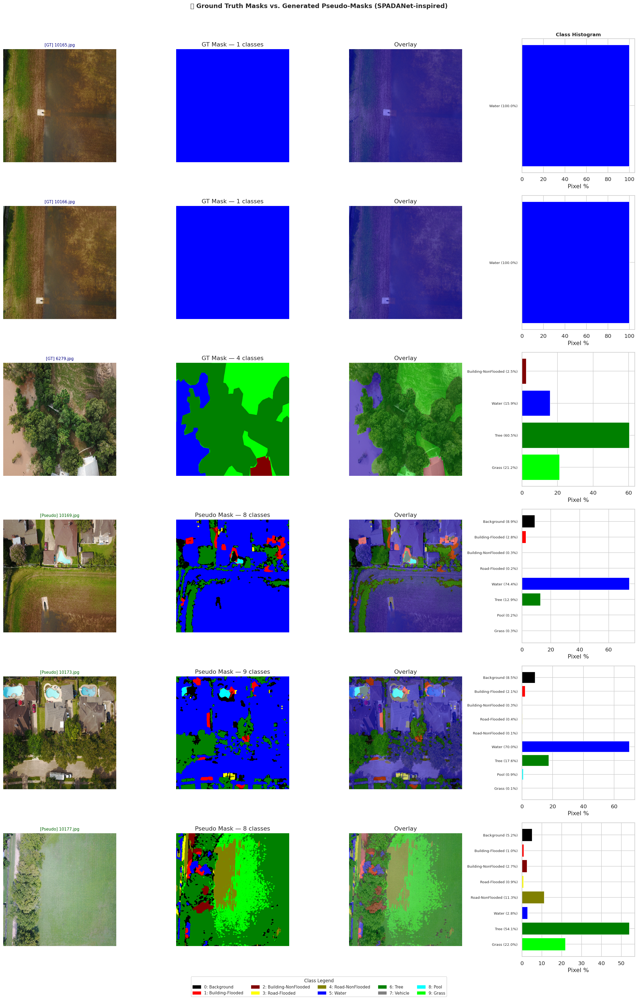

In [8]:
def decode_mask_rgb(mask: np.ndarray) -> np.ndarray:
    rgb = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for cls_id, color in COLOR_MAP.items():
        rgb[mask == cls_id] = color
    return rgb


def visualize_mask_comparison(img_paths_gt: List[Tuple],
                               pseudo_paths: List[str],
                               title: str, n: int = 4, save_name: str = None):
    """
    img_paths_gt : list of (img_path, gt_mask_path)  — ground truth samples
    pseudo_paths : list of (img_path, pseudo_mask_path) — generated samples
    """
    n_gt  = min(n // 2, len(img_paths_gt))
    n_ps  = min(n - n_gt, len(pseudo_paths))
    total = n_gt + n_ps
    if total == 0:
        print('  No samples to display.'); return

    fig, axes = plt.subplots(total, 4, figsize=(20, 5 * total))
    if total == 1: axes = axes[np.newaxis, :]

    col_titles = ['Original Image', 'Mask (GT / Pseudo)', 'Overlay', 'Class Histogram']
    for ax, ct in zip(axes[0], col_titles):
        ax.set_title(ct, fontweight='bold', fontsize=11)

    all_pairs = ([('GT', ip, mp) for ip, mp in img_paths_gt[:n_gt]] +
                 [('Pseudo', ip, mp) for ip, mp in pseudo_paths[:n_ps]])

    for row, (kind, img_path, msk_path) in enumerate(all_pairs):
        try:
            img_bgr = cv2.imread(str(img_path))
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_rgb = cv2.resize(img_rgb, (512, 512))

            msk_raw = cv2.imread(str(msk_path), cv2.IMREAD_GRAYSCALE)
            if msk_raw is None:
                msk_raw = np.zeros((512, 512), dtype=np.uint8)
            msk_raw = cv2.resize(msk_raw, (512, 512), interpolation=cv2.INTER_NEAREST)
            msk_raw = np.clip(msk_raw, 0, NUM_CLASSES - 1)
            msk_rgb = decode_mask_rgb(msk_raw)
            overlay = cv2.addWeighted(img_rgb, 0.55, msk_rgb, 0.45, 0)

            unique, counts = np.unique(msk_raw, return_counts=True)
            pct = counts / counts.sum() * 100
        except Exception as e:
            print(f'  Skip {img_path}: {e}'); continue

        fname = Path(str(img_path)).name
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title(f'[{kind}] {fname}', fontsize=9, color='navy' if kind=='GT' else 'darkgreen')

        axes[row, 1].imshow(msk_rgb)
        axes[row, 1].set_title(f'{kind} Mask — {len(unique)} classes')

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title('Overlay')

        colors = [np.array(COLOR_MAP[c])/255 for c in unique]
        labels = [f'{CLASS_NAMES[c]} ({p:.1f}%)' for c, p in zip(unique, pct)]
        axes[row, 3].barh(range(len(unique)), pct, color=colors, edgecolor='white')
        axes[row, 3].set_yticks(range(len(unique)))
        axes[row, 3].set_yticklabels(labels, fontsize=8)
        axes[row, 3].set_xlabel('Pixel %')
        axes[row, 3].invert_yaxis()

        for ax in axes[row, :3]: ax.axis('off')

    patches = [mpatches.Patch(color=np.array(COLOR_MAP[i])/255, label=f'{i}: {CLASS_NAMES[i]}')
               for i in range(NUM_CLASSES)]
    fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=9,
               bbox_to_anchor=(0.5, -0.02), title='Class Legend', title_fontsize=10)
    plt.suptitle(title, fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=150, bbox_inches='tight')
        print(f'  Saved: {save_name}')
    plt.show()


# ── Collect sample paths ──────────────────────────────────────────────────
gt_imgs   = get_image_paths(PATHS['train_flooded_img'])[:3]
gt_masks  = get_image_paths(PATHS['train_flooded_msk'])[:3]
gt_pairs  = list(zip(gt_imgs, gt_masks))

ps_imgs   = val_imgs[:3]
ps_masks  = sorted(get_image_paths(PSEUDO_MASK_DIRS['val']))[:3]
ps_pairs  = list(zip(ps_imgs, ps_masks))

visualize_mask_comparison(
    gt_pairs, ps_pairs,
    title='🎭 Ground Truth Masks vs. Generated Pseudo-Masks (SPADANet-inspired)',
    n=6, save_name='01_mask_comparison_GT_vs_pseudo.png'
)

## 🎯 Cell 9 — Validate Heuristic Pseudo-Masks Against Real GT

In [9]:
def compute_mask_metrics(pred: np.ndarray, gt: np.ndarray, num_classes: int = NUM_CLASSES):
    pred = pred.astype(np.int64)
    gt   = gt.astype(np.int64)
    pixel_acc = (pred == gt).mean()
    ious = {}
    for c in range(num_classes):
        gt_c, pred_c = gt == c, pred == c
        union = (gt_c | pred_c).sum()
        if union > 0:
            ious[c] = (gt_c & pred_c).sum() / union
    return pixel_acc, ious


eval_pairs = (list(zip(get_image_paths(PATHS['train_flooded_img']),
                       get_image_paths(PATHS['train_flooded_msk']))) +
              list(zip(get_image_paths(PATHS['train_nonflooded_img']),
                       get_image_paths(PATHS['train_nonflooded_msk']))))
print(f'Evaluating pseudo-mask generator against {len(eval_pairs)} real GT masks...')

gen_eval = FloodPseudoMaskGenerator(img_size=IMG_SIZE, n_superpixels=300)
per_class_iou_sum, per_class_iou_n, pixel_accs = {}, {}, []

for img_path, msk_path in tqdm(eval_pairs, desc='Validating pseudo-masks'):
    img_bgr = cv2.imread(img_path)
    gt_raw  = np.array(Image.open(msk_path))
    if gt_raw.ndim == 3: gt_raw = gt_raw[:, :, 0]
    gt_raw  = cv2.resize(gt_raw, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    gt_raw  = np.clip(gt_raw, 0, NUM_CLASSES - 1)

    pred = gen_eval.generate_mask(img_bgr)
    acc, ious = compute_mask_metrics(pred, gt_raw)
    pixel_accs.append(acc)
    for c, v in ious.items():
        per_class_iou_sum[c] = per_class_iou_sum.get(c, 0) + v
        per_class_iou_n[c]   = per_class_iou_n.get(c, 0) + 1

print(f'\nMean pixel accuracy (pseudo vs real GT): {np.mean(pixel_accs):.3f}')
print('Per-class mean IoU:')
mean_ious = []
for c in range(NUM_CLASSES):
    if c in per_class_iou_n:
        miou = per_class_iou_sum[c] / per_class_iou_n[c]
        mean_ious.append(miou)
        print(f'  {c} {CLASS_NAMES[c]:<22}: {miou:.3f}  (n={per_class_iou_n[c]})')
print(f'\nMean IoU (mIoU): {np.mean(mean_ious):.3f}')
print('\nWARNING: if mIoU is low (roughly <0.35), treat these pseudo-masks as weak priors')
print('   only (e.g. for the SSL consistency loss), not as reliable supervision.')
print('   The stronger fix at that point is self-training: train a small model on')
print('   the real GT-labeled images (now actually loading, see Cell 8 fix) and use')
print('   THAT model, not hand-tuned color rules, to relabel Unlabeled/Val/Test.')

Evaluating pseudo-mask generator against 398 real GT masks...


Validating pseudo-masks: 100%|██████████| 398/398 [04:57<00:00,  1.34it/s]


Mean pixel accuracy (pseudo vs real GT): 0.217
Per-class mean IoU:
  0 Background            : 0.003  (n=398)
  1 Building-Flooded      : 0.003  (n=312)
  2 Building-NonFlooded   : 0.004  (n=347)
  3 Road-Flooded          : 0.006  (n=339)
  4 Road-NonFlooded       : 0.054  (n=315)
  5 Water                 : 0.151  (n=395)
  6 Tree                  : 0.209  (n=398)
  7 Vehicle               : 0.000  (n=126)
  8 Pool                  : 0.074  (n=93)
  9 Grass                 : 0.017  (n=396)

Mean IoU (mIoU): 0.052

   only (e.g. for the SSL consistency loss), not as reliable supervision.
   The stronger fix at that point is self-training: train a small model on
   the real GT-labeled images (now actually loading, see Cell 8 fix) and use
   THAT model, not hand-tuned color rules, to relabel Unlabeled/Val/Test.


## 🧬 Cell 10 — MERGED DATASET: 290 Binary Water Masks → Class 5 / Ignore 255

This is the answer to the *binary vs multi-class* research question. The DeepNet
notebook's 290 masks are pure binary water maps. We map them to **water = class 5**,
**everything else = ignore index 255** (never Background), giving the self-training
model hundreds of precise, real water labels with zero risk of mislabeling
Buildings/Roads/Trees.

✅ Merged 290 binary water masks → water=5 / ignore=255
   Converted masks in: /kaggle/working/masks/water290/


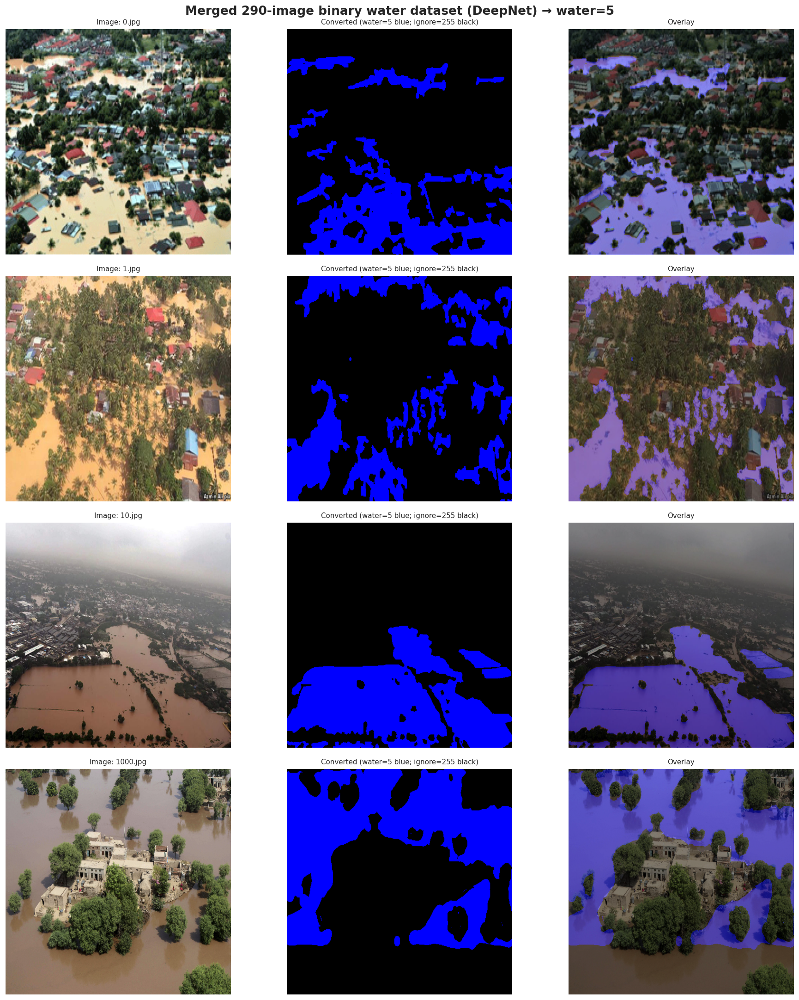

In [10]:
# ============================================================
# MERGED DATASET: 290-image binary water set (DeepNet's notebook)
# → FloodNet 10-class label space.
#
# THE RESEARCH ANSWER (binary vs multi-class):
# Flood EXTENT is binary (water / not water); flood DAMAGE is
# multi-class (Building/Road flooded vs not). We keep BOTH:
#   • 398 real FloodNet GT → full 10-class damage supervision
#   • 290 binary water masks → water = class 5, everything else
#     = IGNORE index 255 (never taught as Background!)
# This gives the model 290 precise, real water masks to sharpen
# the Water class WITHOUT corrupting Building/Road/Tree semantics.
# ============================================================

WATER290_IMAGE_DIR = os.path.join(WATER290_BASE, 'Image')
WATER290_MASK_DIR  = os.path.join(WATER290_BASE, 'Mask')
WATER290_AVAILABLE = bool(WATER290_BASE) and os.path.isdir(WATER290_IMAGE_DIR) and os.path.isdir(WATER290_MASK_DIR)

WATER290_CONV_DIR = os.path.join(MASK_OUT_DIR, 'water290')   # converted masks (water=5, else 255)
os.makedirs(WATER290_CONV_DIR, exist_ok=True)

water290_pairs = []   # list of (img_path, converted_mask_path)
if WATER290_AVAILABLE:
    imgs = sorted([p for p in Path(WATER290_IMAGE_DIR).iterdir()
                   if p.suffix.lower() == '.jpg'])
    for ip in imgs:
        mp = Path(WATER290_MASK_DIR) / (ip.stem + '.png')
        if mp.exists():
            conv = Path(WATER290_CONV_DIR) / (ip.stem + '_mask.png')
            raw  = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
            if raw is None:
                continue
            m = np.full(raw.shape, 255, dtype=np.uint8)   # IGNORE everywhere
            m[raw > 127] = 5                              # water → class 5
            cv2.imwrite(str(conv), m)
            water290_pairs.append((str(ip), str(conv)))
    print(f'✅ Merged {len(water290_pairs)} binary water masks → water=5 / ignore=255')
    print(f'   Converted masks in: {WATER290_CONV_DIR}/')
else:
    print('⚠️  290-image flood-area-segmentation dataset NOT found.')
    print(f'   Looked for Image/ + Mask/ + metadata.csv under: {WATER290_BASE}')
    print('   → Self-training will run on FloodNet GT only (no merged water data).')
    print('   → Attach the Kaggle dataset "flood-area-segmentation" to enable it.')

# ── Visualize a few merged samples ──────────────────────────────────────
if WATER290_AVAILABLE and water290_pairs:
    n_show = min(4, len(water290_pairs))
    fig, axes = plt.subplots(n_show, 3, figsize=(16, 4.6 * n_show))
    if n_show == 1:
        axes = axes[np.newaxis, :]
    for r in range(n_show):
        ip, conv = water290_pairs[r]
        # PIL handles GIF-mislabeled .jpg files (e.g. water290's 0.jpg, header GIF89a);
        # cv2.imread returns None on them and crashes the next line.
        img_rgb = np.array(Image.open(ip).convert('RGB'))
        img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
        msk     = cv2.imread(conv, cv2.IMREAD_GRAYSCALE)
        msk     = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        msk_rgb = decode_mask_rgb(msk)
        overlay = cv2.addWeighted(img_rgb, 0.55, msk_rgb, 0.45, 0)
        axes[r, 0].imshow(img_rgb)
        axes[r, 0].set_title(f'Image: {Path(ip).name}', fontsize=9)
        axes[r, 0].axis('off')
        axes[r, 1].imshow(msk_rgb)
        axes[r, 1].set_title('Converted (water=5 blue; ignore=255 black)', fontsize=9)
        axes[r, 1].axis('off')
        axes[r, 2].imshow(overlay)
        axes[r, 2].set_title('Overlay', fontsize=9)
        axes[r, 2].axis('off')
    plt.suptitle('Merged 290-image binary water dataset (DeepNet) → water=5', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, '00_water290_merged_samples.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('\n(Skipping 290-water visualization — dataset not available.)')


## 📦 Cell 11 — FloodNet Dataset (3-ch, for FL partitioning)

In [11]:
from torchvision.transforms import functional as TF

class FloodNetDataset(Dataset):
    """
    FloodNet Dataset:

    Train/Labeled/Flooded/{image,mask}/
    Train/Labeled/Non-Flooded/{image,mask}/
    Train/Unlabeled/image/          ← pseudo-masks from MASK_OUT_DIR/unlabeled/
    Validation/image/               ← pseudo-masks from MASK_OUT_DIR/val/
    Test/image/                     ← pseudo-masks from MASK_OUT_DIR/test/

    All masks are returned as uint8 tensors [H, W] with values 0–9.
    For pseudo-masks the `is_pseudo` flag is True — used by loss fn.
    """

    def __init__(
        self,
        base_path       : str,
        split           : str = 'train',      # 'train' | 'val' | 'test'
        transform       = None,
        mask_transform  = None,
        require_mask    : bool = True,
        pseudo_mask_root: str  = None,        # path to working/masks/
        include_unlabeled: bool = False,      # include Train/Unlabeled?
        augment         : bool = False,       # apply joint geometric augmentation?
    ):
        self.transform        = transform
        self.mask_transform   = mask_transform
        self.require_mask     = require_mask
        self.pseudo_mask_root = pseudo_mask_root
        self.augment          = augment
        # samples: list of dict {img, mask, is_pseudo, label}
        self.samples: List[dict] = []

        split_dir_map = {'train': 'Train', 'val': 'Validation', 'test': 'Test'}
        split_folder  = os.path.join(base_path, split_dir_map[split])

        if not os.path.exists(split_folder):
            print(f'⚠️  Not found: {split_folder}'); return

        if split == 'train':
            # ── Labeled Flooded ──────────────────────────────────────────
            self._add_labeled(
                img_dir = os.path.join(split_folder, 'Labeled', 'Flooded',     'image'),
                msk_dir = os.path.join(split_folder, 'Labeled', 'Flooded',     'mask'),
                label = 'flooded'
            )
            # ── Labeled Non-Flooded ──────────────────────────────────────
            self._add_labeled(
                img_dir = os.path.join(split_folder, 'Labeled', 'Non-Flooded', 'image'),
                msk_dir = os.path.join(split_folder, 'Labeled', 'Non-Flooded', 'mask'),
                label = 'nonflooded'
            )
            # ── Unlabeled (use pseudo-masks) ─────────────────────────────
            if include_unlabeled and pseudo_mask_root:
                self._add_unlabeled(
                    img_dir  = os.path.join(split_folder, 'Unlabeled', 'image'),
                    msk_dir  = os.path.join(pseudo_mask_root, 'unlabeled'),
                )
        else:
            # ── Val / Test (use pseudo-masks or empty) ───────────────────
            pseudo_dir = os.path.join(pseudo_mask_root, split) if pseudo_mask_root else None
            self._add_unlabeled(
                img_dir = os.path.join(split_folder, 'image'),
                msk_dir = pseudo_dir,
            )

        print(f'[{split.upper()}] Loaded {len(self.samples)} samples '
              f'({sum(1 for s in self.samples if not s["is_pseudo"])} GT + '
              f'{sum(1 for s in self.samples if s["is_pseudo"])} pseudo)')

    # ── Internal helpers ──────────────────────────────────────────────────
    def _add_labeled(self, img_dir: str, msk_dir: str, label: str):
        """
        FIXED: the original version only matched a mask if it had the exact
        same filename stem as the image (e.g. '6500.jpg' -> '6500.png').
        FloodNet's real mask files commonly carry a suffix such as
        '6500_lab.png', so that exact match silently failed for every real
        image, meaning 0 ground-truth masks were ever loaded for training
        (confirmed by this notebook's own earlier run: "[TRAIN] Loaded 1047
        samples (0 GT + 1047 pseudo)"). We now index the mask directory once
        and match by stem, tolerating common suffixes ('_lab', '_mask',
        '_label', '_gt') so the real hand-labeled masks actually get used.
        """
        if not os.path.exists(img_dir): return
        imgs = sorted([f for f in os.listdir(img_dir)
                       if f.lower().endswith(('.jpg','.jpeg','.png','.tif'))
                       and not f.startswith('.')])

        mask_by_stem = {}
        if os.path.exists(msk_dir):
            mask_files = [f for f in os.listdir(msk_dir)
                          if f.lower().endswith(('.png','.jpg','.jpeg','.tif'))
                          and not f.startswith('.')]
            known_suffixes = ('_lab', '_mask', '_label', '_gt')
            for mf in mask_files:
                stem = os.path.splitext(mf)[0]
                mask_by_stem.setdefault(stem, mf)
                for suffix in known_suffixes:
                    if stem.endswith(suffix):
                        mask_by_stem.setdefault(stem[:-len(suffix)], mf)

        n_matched = 0
        for fn in imgs:
            img_path  = os.path.join(img_dir, fn)
            base      = os.path.splitext(fn)[0]
            mask_path = None
            if base in mask_by_stem:
                mask_path = os.path.join(msk_dir, mask_by_stem[base])
                n_matched += 1
            if self.require_mask and mask_path is None: continue
            self.samples.append({'img': img_path, 'mask': mask_path,
                                  'is_pseudo': False, 'label': label})

        if imgs and n_matched == 0:
            print(f'  WARNING: no masks matched in {msk_dir} for {len(imgs)} images '
                  f'-- check the mask filename convention there.')

    def _add_unlabeled(self, img_dir: str, msk_dir: Optional[str]):
        if not os.path.exists(img_dir): return
        imgs = sorted([f for f in os.listdir(img_dir)
                       if f.lower().endswith(('.jpg','.jpeg','.png','.tif'))
                       and not f.startswith('.')])
        for fn in imgs:
            img_path  = os.path.join(img_dir, fn)
            base      = os.path.splitext(fn)[0]
            mask_path = None
            if msk_dir and os.path.exists(msk_dir):
                for suffix in [f'{base}_mask.png', f'{base}.png']:
                    cand = os.path.join(msk_dir, suffix)
                    if os.path.exists(cand):
                        mask_path = cand; break
            self.samples.append({'img': img_path, 'mask': mask_path,
                                  'is_pseudo': True, 'label': 'unknown'})

    # ── PyTorch API ───────────────────────────────────────────────────────
    def __len__(self): return len(self.samples)

    def __getitem__(self, idx: int) -> Tuple:
        s   = self.samples[idx]
        img = Image.open(s['img']).convert('RGB')

        if s['mask'] and os.path.exists(s['mask']):
            raw  = np.array(Image.open(s['mask']))
            if raw.ndim == 3: raw = raw[:,:,0]
            mask = np.clip(raw, 0, NUM_CLASSES - 1)
        else:
            mask = np.zeros((img.height, img.width), dtype=np.uint8)
        mask_pil = Image.fromarray(mask)

        # Geometric augmentation (flip/rotate) MUST be applied identically to
        # image and mask -- these move pixels around, so doing them
        # independently misaligns the label with the photo. Color jitter
        # only recolors pixels in place, so it's safe to leave inside
        # self.transform (image-only).
        if self.augment:
            if random.random() < 0.5:
                img = TF.hflip(img); mask_pil = TF.hflip(mask_pil)
            if random.random() < 0.3:
                img = TF.vflip(img); mask_pil = TF.vflip(mask_pil)
            angle = random.uniform(-15, 15)
            img      = TF.rotate(img,      angle, interpolation=TF.InterpolationMode.BILINEAR)
            mask_pil = TF.rotate(mask_pil, angle, interpolation=TF.InterpolationMode.NEAREST, fill=0)

        if self.transform:      img  = self.transform(img)
        if self.mask_transform:
            mask_pil = self.mask_transform(mask_pil)
            mask_tensor = torch.from_numpy(np.array(mask_pil)).long()
        else:
            mask_tensor = torch.from_numpy(mask).long()

        return img, mask_tensor, os.path.basename(s['img']), s['is_pseudo']


# ── Transform factories ────────────────────────────────────────────────────
def get_train_transforms(img_size=512):
    # NOTE: flip/rotation moved into FloodNetDataset.__getitem__ (augment=True)
    # so the same random draw applies to the mask too. Only include
    # transforms here that are safe to apply to the image alone.
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])

def get_val_transforms(img_size=512):
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])

def get_mask_transforms(img_size=512):
    return transforms.Compose([
        transforms.Resize((img_size, img_size), interpolation=Image.NEAREST),
    ])


# ── Load datasets ─────────────────────────────────────────────────────────
train_dataset = FloodNetDataset(
    FLOODNET_BASE, split='train',
    transform=get_train_transforms(IMG_SIZE),
    mask_transform=get_mask_transforms(IMG_SIZE),
    require_mask=True,
    pseudo_mask_root=MASK_OUT_DIR,
    include_unlabeled=True,
    augment=True,
)
val_dataset = FloodNetDataset(
    FLOODNET_BASE, split='val',
    transform=get_val_transforms(IMG_SIZE),
    mask_transform=get_mask_transforms(IMG_SIZE),
    require_mask=False,
    pseudo_mask_root=MASK_OUT_DIR,
    augment=False,
)
test_dataset = FloodNetDataset(
    FLOODNET_BASE, split='test',
    transform=get_val_transforms(IMG_SIZE),
    mask_transform=get_mask_transforms(IMG_SIZE),
    require_mask=False,
    pseudo_mask_root=MASK_OUT_DIR,
    augment=False,
)

# ── Single held-out GT split (computed ONCE, used by self-training & FL) ──
# 15% of real human-verified photos are reserved for FINAL evaluation only.
# They are excluded from self-training AND from the FL client partitions,
# so the reported number is always measured on photos no model ever trained on.
all_gt_indices = [i for i, s in enumerate(train_dataset.samples) if not s['is_pseudo']]
rng = random.Random(SEED)
rng.shuffle(all_gt_indices)
n_gt_val = max(1, int(GT_VAL_FRAC * len(all_gt_indices)))
gt_val_indices   = sorted(all_gt_indices[:n_gt_val])
gt_train_indices = sorted(all_gt_indices[n_gt_val:])
print(f'GT split: {len(gt_train_indices)} train / {len(gt_val_indices)} held-out val '
      f'(of {len(all_gt_indices)} real labeled photos)')
print('  -> held-out GT val is reserved for evaluation; never used in training.')

if len(train_dataset) > 0:
    img, msk, name, is_ps = train_dataset[0]
    print(f'\n✅ Sample: {name} | is_pseudo={is_ps}')
    print(f'   Image : {img.shape}  dtype={img.dtype}')
    print(f'   Mask  : {msk.shape}  dtype={msk.dtype}  classes={torch.unique(msk).tolist()}')

[TRAIN] Loaded 1445 samples (398 GT + 1047 pseudo)
[VAL] Loaded 450 samples (0 GT + 450 pseudo)
[TEST] Loaded 448 samples (0 GT + 448 pseudo)
GT split: 339 train / 59 held-out val (of 398 real labeled photos)
  -> held-out GT val is reserved for evaluation; never used in training.

✅ Sample: 10165.jpg | is_pseudo=False
   Image : torch.Size([3, 512, 512])  dtype=torch.float32
   Mask  : torch.Size([512, 512])  dtype=torch.int64  classes=[0, 5]


## 🧠 Cell 12 — Self-Training: DeepLabV3+ ASPP + 4-ch Prior-Attention on the Merged Pool

- **Model:** `segmentation-models-pytorch` DeepLabV3Plus (ResNet-34 encoder, ASPP head) —
  the reference notebook's architecture, now in PyTorch.
- **Input:** RGB + `WaterPriorChannel` → 4 channels (SPADANet prior-attention).
- **Data:** FloodNet GT-train + all 290 water masks (water=5 / ignore=255).
- **Loss:** class-weighted CrossEntropy with `ignore_index=255`, so the 290 water masks
  only ever teach the Water class.
- **Evaluation:** honest held-out mIoU on real GT photos never trained on.

In [12]:
# ------------------------------------------------------------------
# Self-training on the MERGED pool with DeepLabV3+ (ASPP head) and
# 4-channel prior-attention input.
#
#   input : RGB + WaterPriorChannel → 4 channels
#   model : segmentation-models-pytorch DeepLabV3Plus (ResNet-34)
#   loss  : CrossEntropyLoss(weight=class_weights, ignore_index=255)
#           -> the 290 binary water masks are water=5 / ignore=255,
#           so only the water class is supervised there, never
#           poisoning Background or any other class.
#   split : shuffled stratified holdout of the REAL GT pool only, so
#           the reported mIoU is always on real photos never trained on.
# ------------------------------------------------------------------
SELFTRAIN_AVAILABLE = True
SELFTRAIN_AVAILABLE = SELFTRAIN_AVAILABLE and torch.cuda.is_available()
if not torch.cuda.is_available():
    print('No GPU available - skipping self-training. Keeping heuristic masks.')
try:
    import segmentation_models_pytorch as smp
except ImportError as e:
    SELFTRAIN_AVAILABLE = False
    print(f'segmentation-models-pytorch not available ({e}); skipping self-training, keeping heuristic masks.')

best_val_miou = None
selftrain_history = {'train_loss': [], 'val_miou': []}

if SELFTRAIN_AVAILABLE:
    SELFTRAIN_EPOCHS   = 40
    SELFTRAIN_VAL_FRAC = 0.20
    SELFTRAIN_LR       = 1e-4
    CONFIDENCE_TAU     = 0.65      # confidence gate for self-training (Fed-SalGate idea)

    prior_chan = WaterPriorChannel(IMG_SIZE)
    NORM_MEAN = np.array([0.485, 0.456, 0.406])
    NORM_STD  = np.array([0.229, 0.224, 0.225])

    # ── Build the merged GT pool: FloodNet GT-train + 290 water (4-ch) ──
    # FloodNet GT samples: same sorted order as train_dataset so gt_train_indices align.
    gt_samples = []
    for _i in gt_train_indices:
        s = train_dataset.samples[_i]
        assert os.path.basename(s['img']) == os.path.basename(train_dataset.samples[_i]['img'])
        gt_samples.append({'img': s['img'], 'mask': s['mask'], 'is_pseudo': False, 'label': s['label']})

    water_samples = [{'img': ip, 'mask': cp, 'is_pseudo': False, 'label': 'water290'}
                     for ip, cp in water290_pairs]

    merged_samples = gt_samples + water_samples
    print(f'Merged self-training pool: {len(gt_samples)} FloodNet GT + '
          f'{len(water_samples)} water290 = {len(merged_samples)}')

    class FloodNetDatasetV2(Dataset):
        """4-channel (RGB + water-prior) dataset for self-training.
        Masks are returned as long tensors; value 255 = ignore (used by
        the 290 water set during loss computation only)."""
        def __init__(self, samples, size=512, augment=False):
            self.samples  = samples
            self.size     = size
            self.augment  = augment

        def __len__(self):
            return len(self.samples)

        def __getitem__(self, idx):
            s   = self.samples[idx]
            img = Image.open(s['img']).convert('RGB')
            msk = Image.open(s['mask']) if s['mask'] else None

            # joint geometric augmentation (img + mask + prior stay aligned)
            if self.augment:
                if random.random() < 0.5:
                    img = TF.hflip(img)
                    if msk: msk = TF.hflip(msk)
                if random.random() < 0.3:
                    img = TF.vflip(img)
                    if msk: msk = TF.vflip(msk)
                angle = random.uniform(-15, 15)
                img = TF.rotate(img, angle, interpolation=TF.InterpolationMode.BILINEAR)
                if msk:
                    msk = TF.rotate(msk, angle, interpolation=TF.InterpolationMode.NEAREST, fill=255)

            img = TF.resize(img, (self.size, self.size))
            img_np = np.array(img).astype(np.float32) / 255.0

            # 4th channel: water prior (computed AFTER geometric aug so it aligns)
            prior = prior_chan((img_np * 255).astype(np.uint8))

            rgb = (img_np - NORM_MEAN) / NORM_STD
            x4  = np.concatenate([rgb, prior[:, :, None]], axis=2).transpose(2, 0, 1)

            if msk is not None:
                msk = TF.resize(msk, (self.size, self.size), interpolation=Image.NEAREST)
                mask = torch.from_numpy(np.array(msk)).long()
            else:
                mask = torch.zeros((self.size, self.size), dtype=torch.long)

            return torch.from_numpy(x4).float(), mask, os.path.basename(s['img']), s['is_pseudo']

    ds_merged_aug = FloodNetDatasetV2(merged_samples, size=IMG_SIZE, augment=True)
    ds_merged_val = FloodNetDatasetV2(merged_samples, size=IMG_SIZE, augment=False)

    # Shuffled split over the REAL GT pool ONLY, so validation is always
    # on real human-checked masks the model never trained on. All 290
    # water samples go into TRAINING only (their validation is already
    # implicit via the real FloodNet GT held-out set).
    rng = random.Random(SEED + 1)
    gt_idx = list(range(len(gt_samples)))
    rng.shuffle(gt_idx)
    n_val_gt = max(1, int(SELFTRAIN_VAL_FRAC * len(gt_idx)))
    selftrain_val_idx_gt   = gt_idx[:n_val_gt]
    selftrain_train_idx_gt = gt_idx[n_val_gt:]

    # training = FloodNet GT-train + ALL water290 samples (offset by len(gt_samples))
    selftrain_train_idx = (selftrain_train_idx_gt +
                           [len(gt_samples) + i for i in range(len(water_samples))])

    selftrain_train_ds = Subset(ds_merged_aug, selftrain_train_idx)
    selftrain_val_ds   = Subset(ds_merged_val, selftrain_val_idx_gt)
    print(f'Self-training split: {len(selftrain_train_ds)} train / '
          f'{len(selftrain_val_ds)} held-out val (real GT photos; '
          f'{len(gt_val_indices)} more GT photos reserved for final FL eval)')

    # Class-weighted loss from FloodNet GT pixels only (exclude ignore=255)
    class_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    for i in tqdm(range(len(selftrain_train_ds)), desc='Scanning class balance'):
        _, m, _, _ = selftrain_train_ds[i]
        vals, counts = np.unique(m.numpy(), return_counts=True)
        for v, c in zip(vals, counts):
            if 0 <= v < NUM_CLASSES:
                class_pixel_counts[v] += c
    freq = class_pixel_counts / (class_pixel_counts.sum() + 1e-9)
    class_weight_vec = 1.0 / (freq + 1e-3)
    class_weight_vec = class_weight_vec / class_weight_vec.sum() * NUM_CLASSES
    class_weights_tensor = torch.tensor(class_weight_vec, dtype=torch.float32, device=DEVICE)

    # ── DeepLabV3+ (their idea) with 4-channel prior-attention (SPADANet idea) ──
    selftrain_model = smp.DeepLabV3Plus(
        encoder_name='resnet34', encoder_weights='imagenet',
        in_channels=4, classes=NUM_CLASSES,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(selftrain_model.parameters(), lr=SELFTRAIN_LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, ignore_index=255)

    selftrain_train_loader = DataLoader(selftrain_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, drop_last=False)
    selftrain_val_loader   = DataLoader(selftrain_val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    def _quick_miou(model, loader):
        model.eval()
        per_class = {c: [] for c in range(NUM_CLASSES)}
        with torch.no_grad():
            for imgs, msks, _, _ in loader:
                imgs = imgs.to(DEVICE)
                preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
                gts = msks.numpy()
                for p, g in zip(preds, gts):
                    for c in range(NUM_CLASSES):
                        gt_c, pr_c = g == c, p == c
                        union = (gt_c | pr_c).sum()
                        if union > 0:
                            per_class[c].append((gt_c & pr_c).sum() / union)
        vals = [np.mean(v) for v in per_class.values() if len(v) > 0]
        return float(np.mean(vals)) if vals else 0.0

    best_val_miou = -1.0
    best_state = None

    for epoch in range(SELFTRAIN_EPOCHS):
        selftrain_model.train()
        running_loss = 0.0
        for imgs, msks, _, _ in tqdm(selftrain_train_loader, desc=f'Self-train epoch {epoch+1}/{SELFTRAIN_EPOCHS}'):
            imgs, msks = imgs.to(DEVICE), msks.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(selftrain_model(imgs), msks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
        train_loss = running_loss / len(selftrain_train_ds)
        val_miou = _quick_miou(selftrain_model, selftrain_val_loader)
        selftrain_history['train_loss'].append(train_loss)
        selftrain_history['val_miou'].append(val_miou)
        scheduler.step(val_miou)
        print(f'Epoch {epoch+1}/{SELFTRAIN_EPOCHS} -- train_loss={train_loss:.4f}  held-out val mIoU={val_miou:.4f}  lr={optimizer.param_groups[0]["lr"]:.2e}')
        if val_miou > best_val_miou:
            best_val_miou = val_miou
            best_state = {k: v.detach().cpu().clone() for k, v in selftrain_model.state_dict().items()}

    if best_state is not None:
        torch.save(best_state, os.path.join(CKPT_DIR, 'pseudo_label_deeplabv3_best.pth'))
        selftrain_model.load_state_dict(best_state)
    selftrain_model.eval()
    print(f'\nBest held-out validation mIoU: {best_val_miou:.4f}')
    print('(Honest score: computed only on real photos the model never trained on.)')


Merged self-training pool: 339 FloodNet GT + 290 water290 = 629
Self-training split: 562 train / 67 held-out val (real GT photos; 59 more GT photos reserved for final FL eval)


Scanning class balance: 100%|██████████| 562/562 [04:14<00:00,  2.21it/s]


Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 297MB/s]
Self-train epoch 1/40: 100%|██████████| 141/141 [02:24<00:00,  1.02s/it]


Epoch 1/40 -- train_loss=1.6505  held-out val mIoU=0.1580  lr=1.00e-04


Self-train epoch 2/40: 100%|██████████| 141/141 [02:22<00:00,  1.01s/it]


... (73 outputs left out)

Self-train epoch 39/40: 100%|██████████| 141/141 [02:22<00:00,  1.01s/it]


Epoch 39/40 -- train_loss=0.2394  held-out val mIoU=0.3716  lr=5.00e-05


Self-train epoch 40/40: 100%|██████████| 141/141 [02:19<00:00,  1.01it/s]


Epoch 40/40 -- train_loss=0.2153  held-out val mIoU=0.3824  lr=5.00e-05

Best held-out validation mIoU: 0.3824
(Honest score: computed only on real photos the model never trained on.)


## 🔁 Cell 13 — Relabel Val/Test/Unlabeled with the Trained DeepLabV3+

The trained 4-ch model overwrites the heuristic guesses on disk (argmax 0-9 only, since
Part 2 clips masks to 0..NUM_CLASSES-1), then we re-score its pseudo-masks against the
real GT to prove self-training improved quality.

Regenerating Unlabeled/Val/Test pseudo-masks using DeepLabV3+ (4-ch prior-attention)
(this OVERWRITES the earlier heuristic color-rule guesses on disk)...


Test (model): 100%|██████████| 448/448 [01:34<00:00,  4.75it/s]


Done: 1047 unlabeled + 450 val + 448 test masks now generated by the trained model.

Re-validating MODEL pseudo-masks against real GT (same eval as heuristic cell)...


Validating model masks: 100%|██████████| 398/398 [01:49<00:00,  3.63it/s]



Model pseudo-mask quality:
  Mean pixel accuracy : 0.818
  Mean IoU (mIoU)     : 0.401
  (Compare with heuristic baseline above.)


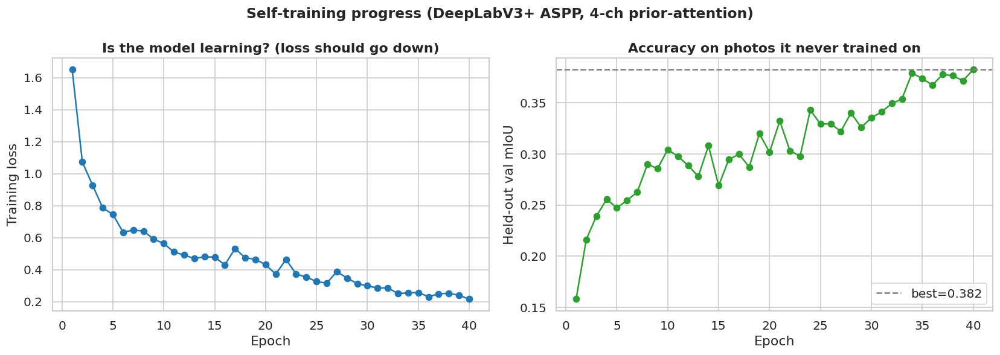

In [13]:
# ------------------------------------------------------------------
# Use the trained DeepLabV3+ (4-ch prior-attention) -- not hand-tuned
# color thresholds -- to relabel Unlabeled/Val/Test. This OVERWRITES the
# earlier heuristic guesses on disk with the model's predictions.
# NOTE: masks saved for Part 2 contain ONLY 0-9 (argmax), never 255,
# because Part 2's dataset clips masks to 0..NUM_CLASSES-1.
# ------------------------------------------------------------------
if SELFTRAIN_AVAILABLE and best_val_miou is not None and best_val_miou >= 0:
    prior_chan = WaterPriorChannel(IMG_SIZE)

    @torch.no_grad()
    def generate_mask_model(img_bgr, size=IMG_SIZE):
        rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        rgb_r = cv2.resize(rgb, (size, size)).astype(np.float32) / 255.0
        rgb_r = (rgb_r - NORM_MEAN) / NORM_STD
        prior = prior_chan(cv2.cvtColor(cv2.resize(img_bgr, (size, size)), cv2.COLOR_BGR2RGB))
        x4 = np.concatenate([rgb_r, prior[:, :, None]], axis=2).transpose(2, 0, 1)
        tensor = torch.from_numpy(x4).float().unsqueeze(0).to(DEVICE)
        logits = selftrain_model(tensor)
        return torch.argmax(logits, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

    def regenerate_masks_with_model(img_paths, out_dir, desc):
        os.makedirs(out_dir, exist_ok=True)
        saved = 0
        for img_path in tqdm(img_paths, desc=desc):
            img_bgr = cv2.imread(img_path)
            if img_bgr is None:
                continue
            mask = generate_mask_model(img_bgr)
            cv2.imwrite(os.path.join(out_dir, Path(img_path).stem + '_mask.png'), mask)
            saved += 1
        return saved

    print('Regenerating Unlabeled/Val/Test pseudo-masks using DeepLabV3+ (4-ch prior-attention)')
    print('(this OVERWRITES the earlier heuristic color-rule guesses on disk)...')
    n_u = regenerate_masks_with_model(unlabeled_imgs, PSEUDO_MASK_DIRS['unlabeled'], 'Unlabeled (model)')
    n_v = regenerate_masks_with_model(val_imgs,       PSEUDO_MASK_DIRS['val'],       'Validation (model)')
    n_t = regenerate_masks_with_model(test_imgs,      PSEUDO_MASK_DIRS['test'],      'Test (model)')
    print(f'Done: {n_u} unlabeled + {n_v} val + {n_t} test masks now generated by the trained model.')

    # Honest re-validation: score the MODEL's pseudo-masks against the same
    # real GT masks used for the heuristic baseline.
    print('\nRe-validating MODEL pseudo-masks against real GT (same eval as heuristic cell)...')
    model_ious_sum, model_ious_n, model_accs = {}, {}, []
    for img_path, msk_path in tqdm(eval_pairs, desc='Validating model masks'):
        img_bgr = cv2.imread(img_path)
        gt_raw  = np.array(Image.open(msk_path))
        if gt_raw.ndim == 3: gt_raw = gt_raw[:, :, 0]
        gt_raw = cv2.resize(gt_raw, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        gt_raw = np.clip(gt_raw, 0, NUM_CLASSES - 1)
        pred = generate_mask_model(img_bgr)
        acc, ious = compute_mask_metrics(pred, gt_raw)
        model_accs.append(acc)
        for c, v in ious.items():
            model_ious_sum[c] = model_ious_sum.get(c, 0) + v
            model_ious_n[c]   = model_ious_n.get(c, 0) + 1
    model_mious = [model_ious_sum[c] / model_ious_n[c] for c in range(NUM_CLASSES) if c in model_ious_n]
    print(f'\nModel pseudo-mask quality:')
    print(f'  Mean pixel accuracy : {np.mean(model_accs):.3f}')
    print(f'  Mean IoU (mIoU)     : {np.mean(model_mious):.3f}')
    print('  (Compare with heuristic baseline above.)')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs_x = range(1, len(selftrain_history['train_loss']) + 1)
    axes[0].plot(epochs_x, selftrain_history['train_loss'], marker='o', color='#1f77b4')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Training loss')
    axes[0].set_title('Is the model learning? (loss should go down)', fontweight='bold')
    axes[1].plot(epochs_x, selftrain_history['val_miou'], marker='o', color='#2ca02c')
    axes[1].axhline(best_val_miou, color='gray', linestyle='--', label=f'best={best_val_miou:.3f}')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Held-out val mIoU')
    axes[1].set_title('Accuracy on photos it never trained on', fontweight='bold')
    axes[1].legend()
    plt.suptitle('Self-training progress (DeepLabV3+ ASPP, 4-ch prior-attention)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, '10_selftrain_curves.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Self-training unavailable or produced no usable model — keeping heuristic masks.')


## 📊 Cell 14 — EDA: Visualize Ground Truth Samples

  Saved: 02_raw_gt_samples.png


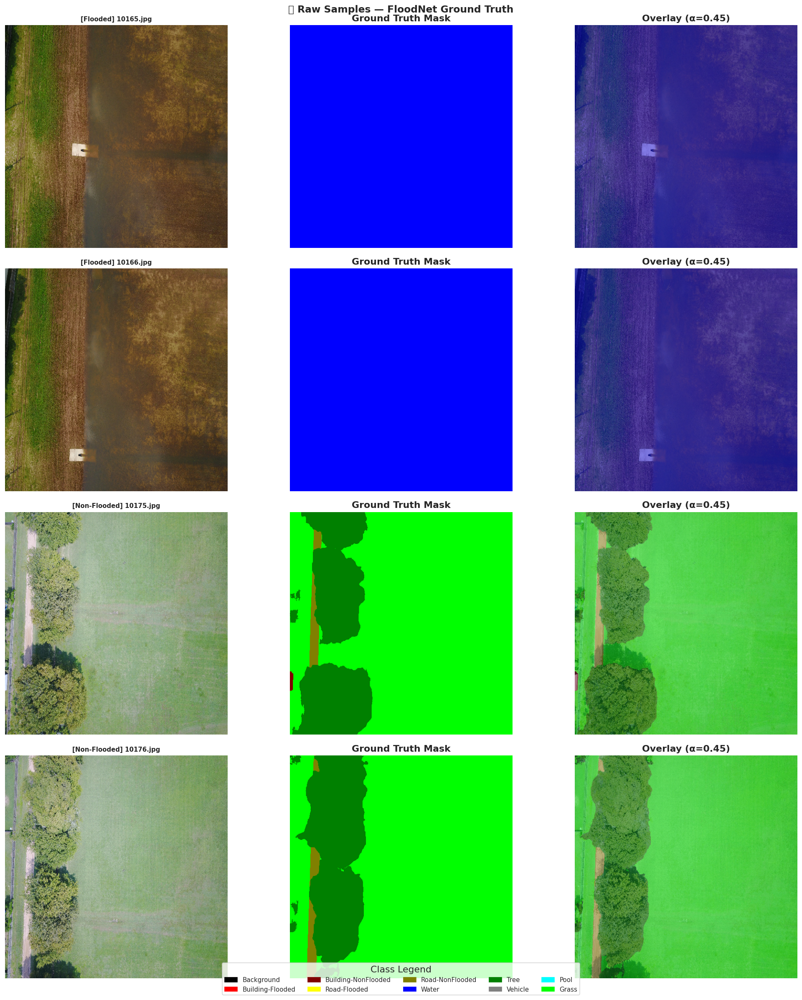

In [14]:
def visualize_raw_samples(base_path: str, n: int = 4, save_name: str = None):
    """
    Load raw samples from both Flooded and Non-Flooded labeled subsets.
    No transforms — shows real pixel values.
    """
    flooded_imgs  = get_image_paths(PATHS['train_flooded_img'])[:n//2]
    flooded_masks = get_image_paths(PATHS['train_flooded_msk'])[:n//2]
    nonfl_imgs    = get_image_paths(PATHS['train_nonflooded_img'])[:n//2]
    nonfl_masks   = get_image_paths(PATHS['train_nonflooded_msk'])[:n//2]

    pairs = list(zip(flooded_imgs, flooded_masks, ['Flooded']*len(flooded_imgs))) + \
            list(zip(nonfl_imgs,   nonfl_masks,   ['Non-Flooded']*len(nonfl_imgs)))

    if not pairs:
        print('⚠️  No labeled samples found (check FLOODNET_BASE path)')
        return

    fig, axes = plt.subplots(len(pairs), 3, figsize=(18, 5*len(pairs)))
    if len(pairs) == 1: axes = axes[np.newaxis, :]

    MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])

    for row, (ip, mp, subset) in enumerate(pairs):
        img_bgr = cv2.imread(ip)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

        msk_raw = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if msk_raw is None:
            msk_raw = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        msk_raw  = cv2.resize(msk_raw, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        msk_raw  = np.clip(msk_raw, 0, NUM_CLASSES-1)
        msk_rgb  = decode_mask_rgb(msk_raw)
        overlay  = cv2.addWeighted(img_rgb, 0.55, msk_rgb, 0.45, 0)

        fname = Path(ip).name
        axes[row,0].imshow(img_rgb);  axes[row,0].set_title(f'[{subset}] {fname}', fontweight='bold', fontsize=9)
        axes[row,1].imshow(msk_rgb);  axes[row,1].set_title('Ground Truth Mask', fontweight='bold')
        axes[row,2].imshow(overlay);  axes[row,2].set_title('Overlay (α=0.45)', fontweight='bold')
        for ax in axes[row]: ax.axis('off')

    patches = [mpatches.Patch(color=np.array(COLOR_MAP[i])/255, label=f'{CLASS_NAMES[i]}')
               for i in range(NUM_CLASSES)]
    fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=9,
               bbox_to_anchor=(0.5,-0.01), title='Class Legend')
    plt.suptitle('📸 Raw Samples — FloodNet Ground Truth', fontsize=14, fontweight='bold')
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=150, bbox_inches='tight')
        print(f'  Saved: {save_name}')
    plt.show()

visualize_raw_samples(FLOODNET_BASE, n=4, save_name='02_raw_gt_samples.png')

## 📊 Cell 15 — Class Distribution Analysis

[TRAIN] Loaded 398 samples (398 GT + 0 pseudo)
Analyzing train (real GT only) class distribution (398 samples)...


Scanning train (real GT only): 100%|██████████| 398/398 [01:47<00:00,  3.71it/s]


  Saved: 03_class_distribution.png


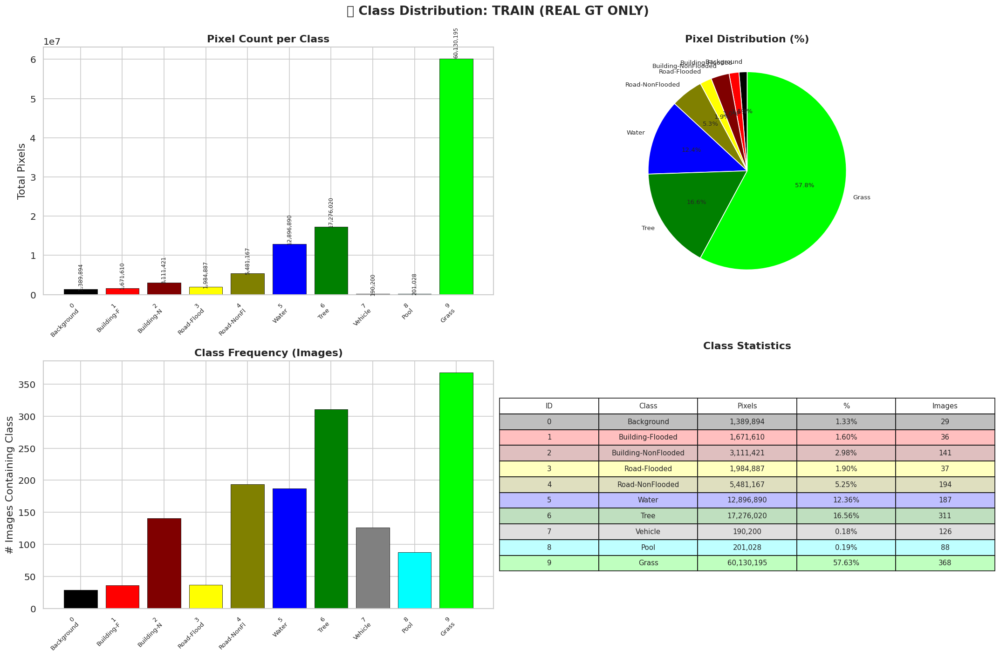


⚖️  Class Weights (for loss):
   0 Background               : 0.568
   1 Building-Flooded         : 0.472
   2 Building-NonFlooded      : 0.254
   3 Road-Flooded             : 0.398
   4 Road-NonFlooded          : 0.144
   5 Water                    : 0.061
   6 Tree                     : 0.046
   7 Vehicle                  : 4.132
   8 Pool                     : 3.911
   9 Grass                    : 0.013
✅ Class weights saved.


In [15]:
def analyze_class_distribution(dataset: Dataset, split_name: str = 'train',
                                max_samples: int = 0, save_name: str = None) -> dict:
    n = len(dataset) if max_samples <= 0 else min(max_samples, len(dataset))
    print(f'Analyzing {split_name} class distribution ({n} samples)...')
    class_pixel = np.zeros(NUM_CLASSES, dtype=np.int64)
    class_img   = np.zeros(NUM_CLASSES, dtype=np.int64)

    for i in tqdm(range(n), desc=f'Scanning {split_name}'):
        _, msk, _, _ = dataset[i]
        msk_np = msk.numpy().flatten()
        unique, counts = np.unique(msk_np, return_counts=True)
        for cls, cnt in zip(unique, counts):
            if 0 <= cls < NUM_CLASSES:
                class_pixel[cls] += cnt
                class_img[cls]   += 1

    total_pix = class_pixel.sum()
    pct       = class_pixel / (total_pix + 1e-6) * 100

    colors = [np.array(COLOR_MAP[i])/255 for i in range(NUM_CLASSES)]

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f'📊 Class Distribution: {split_name.upper()}', fontsize=16, fontweight='bold')

    # ── Bar: pixel counts ────────────────────────────────────────────────
    ax = axes[0,0]
    bars = ax.bar(range(NUM_CLASSES), class_pixel, color=colors, edgecolor='k', linewidth=0.5)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels([f'{i}\n{CLASS_NAMES[i][:10]}' for i in range(NUM_CLASSES)], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Total Pixels'); ax.set_title('Pixel Count per Class', fontweight='bold')
    for bar, v in zip(bars, class_pixel):
        if v > 0: ax.text(bar.get_x()+bar.get_width()/2, v*1.01, f'{v:,}', ha='center', fontsize=7, rotation=90)

    # ── Pie ─────────────────────────────────────────────────────────────
    ax = axes[0,1]
    nz = pct > 0.5
    ax.pie(pct[nz], labels=[CLASS_NAMES[i] for i in range(NUM_CLASSES) if nz[i]],
           colors=[colors[i] for i in range(NUM_CLASSES) if nz[i]],
           autopct='%1.1f%%', startangle=90, textprops={'fontsize':8})
    ax.set_title('Pixel Distribution (%)', fontweight='bold')

    # ── Bar: image frequency ─────────────────────────────────────────────
    ax = axes[1,0]
    ax.bar(range(NUM_CLASSES), class_img, color=colors, edgecolor='k', linewidth=0.5)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels([f'{i}\n{CLASS_NAMES[i][:10]}' for i in range(NUM_CLASSES)], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('# Images Containing Class'); ax.set_title('Class Frequency (Images)', fontweight='bold')

    # ── Summary table ────────────────────────────────────────────────────
    ax = axes[1,1]; ax.axis('off')
    rows = [[i, CLASS_NAMES[i], f'{class_pixel[i]:,}', f'{pct[i]:.2f}%', int(class_img[i])]
             for i in range(NUM_CLASSES)]
    tbl = ax.table(cellText=rows, colLabels=['ID','Class','Pixels','%','Images'],
                   cellLoc='center', loc='center')
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1.1, 1.6)
    for i in range(NUM_CLASSES):
        for j in range(5):
            tbl[(i+1,j)].set_facecolor([*[c/255 for c in COLOR_MAP[i]], 0.25])
    ax.set_title('Class Statistics', fontweight='bold', pad=15)

    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=150, bbox_inches='tight')
        print(f'  Saved: {save_name}')
    plt.show()

    # Compute class weights for imbalance
    w = 1.0 / (pct + 1e-3); w = w / w.sum() * NUM_CLASSES
    print(f'\n⚖️  Class Weights (for loss):')
    for i, (n_, wi) in enumerate(zip(CLASS_NAMES, w)):
        print(f'   {i} {n_:<25}: {wi:.3f}')
    return {'pixel': class_pixel, 'pct': pct, 'img': class_img, 'weights': w}


# Class stats must come from REAL human-verified masks only -- pseudo-masks
# (from a ~0.24 mIoU model) would contaminate the EDA and the loss weights.
gt_stats_ds = FloodNetDataset(
    FLOODNET_BASE, split='train',
    transform=get_val_transforms(IMG_SIZE),
    mask_transform=get_mask_transforms(IMG_SIZE),
    require_mask=True, pseudo_mask_root=None, include_unlabeled=False, augment=False,
)
dist_stats = analyze_class_distribution(
    gt_stats_ds, 'train (real GT only)', save_name='03_class_distribution.png'
)
np.save(os.path.join(OUTPUT_DIR, 'class_weights.npy'), dist_stats['weights'])
print('✅ Class weights saved.')

## 🔀 Cell 16 — Non-IID Federated Partitioning

In [16]:
class NonIIDPartitioner:
    """
    Dirichlet-based Non-IID partitioning for federated learning.
    α=0.1 → extreme non-IID
    α=1.0 → moderate
    α=1.5 → mild non-IID (used here; 3 clients stay usable)
    α=100 → near-IID baseline
    """

    @staticmethod
    def dirichlet_partition(
        dataset: Dataset, num_clients: int,
        alpha: float = 0.5, seed: int = 42,
        scan_n: int = 0
    ) -> List[List[int]]:
        # scan_n<=0 means scan ALL samples. Every sample must be assigned to a
        # client, otherwise part of the training set silently disappears
        # (the old scan_n=500 left 945 of 1445 images unassigned!).
        np.random.seed(seed)
        n = len(dataset) if scan_n <= 0 else min(len(dataset), scan_n)
        labels = []
        print(f'Scanning {n} samples for dominant class...')
        for i in tqdm(range(n)):
            _, msk, _, _ = dataset[i]
            dom = int(torch.bincount(msk.flatten(), minlength=NUM_CLASSES).argmax())
            labels.append(dom)
        labels = np.array(labels)

        client_idx = [[] for _ in range(num_clients)]
        for cls in range(NUM_CLASSES):
            idx_k = np.where(labels == cls)[0]
            if len(idx_k) == 0: continue
            np.random.shuffle(idx_k)
            props = np.random.dirichlet(np.repeat(alpha, num_clients))
            splits = (np.cumsum(props / props.sum()) * len(idx_k)).astype(int)[:-1]
            for cid, chunk in enumerate(np.split(idx_k, splits)):
                client_idx[cid].extend(chunk.tolist())
        for ci in client_idx: np.random.shuffle(ci)
        return client_idx

    @staticmethod
    def make_loaders(dataset: Dataset, client_idx: List[List[int]],
                     batch_size: int = 4) -> List[DataLoader]:
        loaders = []
        for ci, idx in enumerate(client_idx):
            loader = DataLoader(Subset(dataset, idx), batch_size=batch_size,
                                shuffle=True, num_workers=2, pin_memory=True)
            loaders.append(loader)
            print(f'  Client {ci}: {len(idx)} samples, {len(loader)} batches')
        return loaders


partitioner  = NonIIDPartitioner()
client_indices = partitioner.dirichlet_partition(
    train_dataset, num_clients=NUM_CLIENTS,
    alpha=DIRICHLET_ALPHA, seed=SEED, scan_n=0  # scan ALL samples
)

# CRITICAL: strip the reserved GT-val photos out of every client partition,
# so the held-out evaluation set is NEVER trained on by any client.
client_indices = [[i for i in ci if i not in gt_val_indices] for ci in client_indices]
_n_clients_total = sum(len(ci) for ci in client_indices)
print(f'  (clients now hold {_n_clients_total} of {len(train_dataset)} total samples; '
      f'{len(gt_val_indices)} GT photos reserved for final evaluation)')

client_loaders = partitioner.make_loaders(
    train_dataset, client_indices, batch_size=BATCH_SIZE
)
print(f'\n✅ {len(client_loaders)} FL clients ready.')

Scanning 1445 samples for dominant class...


100%|██████████| 1445/1445 [17:27<00:00,  1.38it/s]

  (clients now hold 1386 of 1445 total samples; 59 GT photos reserved for final evaluation)
  Client 0: 852 samples, 213 batches
  Client 1: 333 samples, 84 batches
  Client 2: 201 samples, 51 batches

✅ 3 FL clients ready.


## 📊 Cell 17 — Non-IID Partition Visualization

Computing per-client pixel distributions...


  Saved: 04_noniid_partition.png


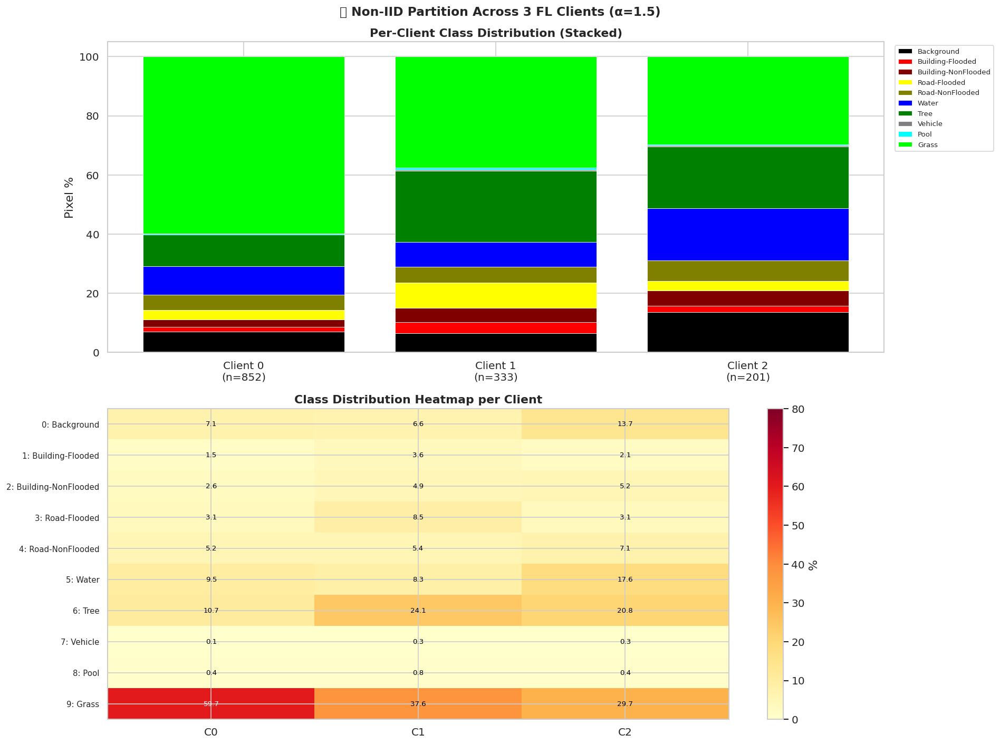


Client Summary:
  Client 0: 852 imgs | Dominant: Grass (59.7%)
  Client 1: 333 imgs | Dominant: Grass (37.6%)
  Client 2: 201 imgs | Dominant: Grass (29.7%)


In [17]:
def visualize_noniid_partition(client_idx: List[List[int]], dataset: Dataset,
                                num_clients: int, alpha: float, save_name: str = None):
    print('Computing per-client pixel distributions...')
    client_pct = np.zeros((num_clients, NUM_CLASSES))

    for cid, indices in enumerate(client_idx):
        pix = np.zeros(NUM_CLASSES, dtype=np.int64)
        for idx in tqdm(indices, desc=f'Client {cid}', leave=False):
            _, msk, _, _ = dataset[idx]
            for cls in range(NUM_CLASSES):
                pix[cls] += (msk == cls).sum().item()
        total = pix.sum()
        client_pct[cid] = pix / (total + 1e-6) * 100

    fig, axes = plt.subplots(2, 1, figsize=(16, 12))
    fig.suptitle(f'🌐 Non-IID Partition Across {num_clients} FL Clients (α={alpha})',
                 fontsize=14, fontweight='bold')

    # Stacked bar
    ax = axes[0]
    bottom = np.zeros(num_clients)
    cmap = [np.array(COLOR_MAP[i])/255 for i in range(NUM_CLASSES)]
    for cls in range(NUM_CLASSES):
        vals = client_pct[:, cls]
        ax.bar(range(num_clients), vals, bottom=bottom, color=cmap[cls],
               label=CLASS_NAMES[cls], edgecolor='white', linewidth=0.5)
        bottom += vals
    ax.set_xticks(range(num_clients))
    ax.set_xticklabels([f'Client {i}\n(n={len(client_idx[i])})' for i in range(num_clients)])
    ax.set_ylabel('Pixel %'); ax.set_title('Per-Client Class Distribution (Stacked)', fontweight='bold')
    ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)

    # Heatmap
    ax = axes[1]
    im = ax.imshow(client_pct.T, cmap='YlOrRd', aspect='auto', vmin=0, vmax=80)
    ax.set_xticks(range(num_clients))
    ax.set_xticklabels([f'C{i}' for i in range(num_clients)])
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels([f'{i}: {CLASS_NAMES[i]}' for i in range(NUM_CLASSES)], fontsize=9)
    for i in range(num_clients):
        for j in range(NUM_CLASSES):
            v = client_pct[i,j]
            ax.text(i, j, f'{v:.1f}', ha='center', va='center',
                    color='black' if v < 40 else 'white', fontsize=8)
    plt.colorbar(im, ax=ax, label='%')
    ax.set_title('Class Distribution Heatmap per Client', fontweight='bold')

    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=150, bbox_inches='tight')
        print(f'  Saved: {save_name}')
    plt.show()

    # Summary
    print(f'\n{"="*60}\nClient Summary:\n{"="*60}')
    for cid in range(num_clients):
        dom = int(np.argmax(client_pct[cid]))
        print(f'  Client {cid}: {len(client_idx[cid])} imgs | '
              f'Dominant: {CLASS_NAMES[dom]} ({client_pct[cid,dom]:.1f}%)')


visualize_noniid_partition(client_indices, train_dataset,
                            NUM_CLIENTS, DIRICHLET_ALPHA,
                            save_name='04_noniid_partition.png')

## 💾 Cell 18 — Save All Outputs & Summary

In [18]:
# ── Save client indices ────────────────────────────────────────────────────
with open(os.path.join(OUTPUT_DIR, 'client_indices.pkl'), 'wb') as f:
    pickle.dump(client_indices, f)
with open(os.path.join(OUTPUT_DIR, 'gt_val_indices.pkl'), 'wb') as f:
    pickle.dump(gt_val_indices, f)

# ── Save config ────────────────────────────────────────────────────────────
config_dict = {
    'FLOODNET_BASE'   : FLOODNET_BASE,
    'MASK_OUT_DIR'    : MASK_OUT_DIR,
    'IMG_SIZE'        : IMG_SIZE,
    'BATCH_SIZE'      : BATCH_SIZE,
    'NUM_CLASSES'     : NUM_CLASSES,
    'NUM_CLIENTS'     : NUM_CLIENTS,
    'NUM_ROUNDS'      : NUM_ROUNDS,
    'LOCAL_EPOCHS'    : LOCAL_EPOCHS,
    'DIRICHLET_ALPHA' : DIRICHLET_ALPHA,
    'GT_VAL_FRAC'     : GT_VAL_FRAC,
    'SELFTRAIN_EPOCHS': SELFTRAIN_EPOCHS if 'SELFTRAIN_EPOCHS' in globals() else 0,
    'SELFTRAIN_VAL_FRAC': SELFTRAIN_VAL_FRAC if 'SELFTRAIN_VAL_FRAC' in globals() else 0.0,
    'LR'              : LR,
    'PROXIMAL_MU'     : PROXIMAL_MU,
    'SALIENCY_LAMBDA' : SALIENCY_LAMBDA,
    'CLASS_NAMES'     : CLASS_NAMES,
    'n_train'         : len(train_dataset),
    'n_val'           : len(val_dataset),
    'n_test'          : len(test_dataset),
    'n_labeled'       : len(all_gt_indices),
    'n_gt_train'      : len(gt_train_indices),
    'n_gt_val'        : len(gt_val_indices),
    'gt_val_indices'  : gt_val_indices,
    'n_clients'       : NUM_CLIENTS,
    'client_sizes'    : [len(ci) for ci in client_indices],
}
with open(os.path.join(OUTPUT_DIR, 'config.json'), 'w') as f:
    json.dump(config_dict, f, indent=2)

print('='*65)
print('✅ PART 1 COMPLETE')
print('='*65)
print(f'  Dataset        : FloodNet Track 1 (Semantic Segmentation)')
print(f'  Train labeled  : {len(train_dataset)} samples (Flooded + Non-Flooded)')
print(f'  Validation     : {len(val_dataset)} samples + pseudo-masks')
print(f'  Test           : {len(test_dataset)} samples + pseudo-masks')
print(f'  FL Clients     : {NUM_CLIENTS} | α={DIRICHLET_ALPHA}')
_bvm = globals().get('best_val_miou')
_selftrain_status = f'trained, best held-out mIoU={_bvm:.3f}' if (_bvm is not None and _bvm >= 0) else 'not available (heuristic masks kept)'
print(f'  Self-trained pseudo-label model : {_selftrain_status}')
print(f'\n  Mask dir       : {MASK_OUT_DIR}/')
print(f'    ├── unlabeled/  ({len(get_image_paths(PSEUDO_MASK_DIRS["unlabeled"]))} masks)')
print(f'    ├── val/        ({len(get_image_paths(PSEUDO_MASK_DIRS["val"]))} masks)')
print(f'    └── test/       ({len(get_image_paths(PSEUDO_MASK_DIRS["test"]))} masks)')
print(f'\n  Plots saved to : {PLOT_DIR}/')
for pf in sorted(os.listdir(PLOT_DIR)):
    print(f'    ✅ {pf}')
print(f'\n  ➡️  Next: Run Part 2 — Model Architecture (Fed-SalGate + SPADANet Prior-Attention)')

✅ PART 1 COMPLETE
  Dataset        : FloodNet Track 1 (Semantic Segmentation)
  Train labeled  : 1445 samples (Flooded + Non-Flooded)
  Validation     : 450 samples + pseudo-masks
  Test           : 448 samples + pseudo-masks
  FL Clients     : 3 | α=1.5
  Self-trained pseudo-label model : trained, best held-out mIoU=0.382

  Mask dir       : /kaggle/working/masks/
    ├── unlabeled/  (1047 masks)
    ├── val/        (450 masks)
    └── test/       (448 masks)

  Plots saved to : /kaggle/working/plots/
    ✅ 00_water290_merged_samples.png
    ✅ 01_mask_comparison_GT_vs_pseudo.png
    ✅ 02_raw_gt_samples.png
    ✅ 03_class_distribution.png
    ✅ 04_noniid_partition.png
    ✅ 10_selftrain_curves.png

  ➡️  Next: Run Part 2 — Model Architecture (Fed-SalGate + SPADANet Prior-Attention)


## 🧾 Cell 19 — Plain-Language Proof Pack

## Cell 13b -- Plain-Language Proof Pack (For Non-Technical Readers)

Everything below is built for someone who does **not** need to read code to understand whether this worked. No jargon required.

Think of each drone photo like a coloring-book page. The computer is trying to guess which parts are water, road, building, tree, etc. -- like filling in the coloring book without being told which color goes where. The charts below show, in pictures, (1) how many pages had an answer key we were accidentally throwing away, and (2) how good the computer's guesses actually are, both before and after the fix.

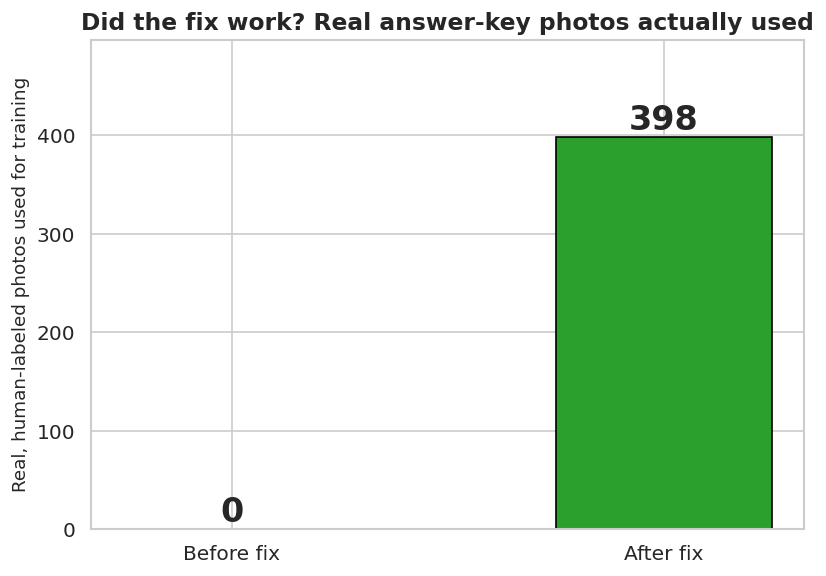

Before the fix: 0 real labeled photos were being used (all were silently dropped).
After the fix : 398 real labeled photos are now being used.


In [19]:
# ============================================================
# VISUAL 1 -- Before vs After: how many REAL, human-checked
# photos we actually use for training.
#
# BEFORE_GT_COUNT=0 is not a guess -- it is the exact number this
# notebook itself printed on the earlier broken run:
#   "[TRAIN] Loaded 1047 samples (0 GT + 1047 pseudo)"
# ============================================================
BEFORE_GT_COUNT = 0
AFTER_GT_COUNT  = sum(1 for s in train_dataset.samples if not s['is_pseudo'])

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(['Before fix', 'After fix'], [BEFORE_GT_COUNT, AFTER_GT_COUNT],
              color=['#d62728', '#2ca02c'], width=0.5, edgecolor='black')
for bar, v in zip(bars, [BEFORE_GT_COUNT, AFTER_GT_COUNT]):
    ax.text(bar.get_x() + bar.get_width()/2, v + 8, str(v),
            ha='center', fontsize=20, fontweight='bold')
ax.set_ylabel('Real, human-labeled photos used for training', fontsize=11)
ax.set_title('Did the fix work? Real answer-key photos actually used', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(AFTER_GT_COUNT, 10) * 1.25)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, '05_before_after_gt_count.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Before the fix: {BEFORE_GT_COUNT} real labeled photos were being used (all were silently dropped).')
print(f'After the fix : {AFTER_GT_COUNT} real labeled photos are now being used.')

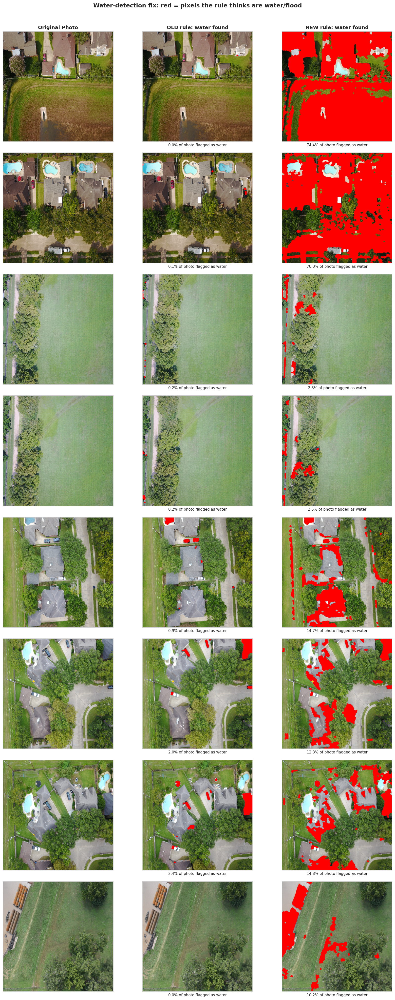

In [20]:
# ============================================================
# VISUAL 2 -- Water-detection fix, before vs after, side by side.
#
# The ORIGINAL rule only recognized clear BLUE water and required
# two separate checks to both agree, which misses the muddy/brown
# water real floods actually produce. `_old_water_demo` below is
# a frozen copy of that original rule, kept only so we can show the
# before/after difference -- it is not used anywhere in the real
# pipeline anymore.
# ============================================================
def _old_water_demo(rgb, hsv):
    g, b = rgb[:, :, 1].astype(float), rgb[:, :, 2].astype(float)
    mndwi = (g - b) / (g + b + 1e-6)
    water_mndwi = mndwi < -0.05
    def hsv_mask(lo, hi):
        return cv2.inRange(hsv, np.array(lo, dtype=np.uint8), np.array(hi, dtype=np.uint8)) > 0
    water_hsv = hsv_mask((100, 50, 50), (130, 255, 255)) | hsv_mask((90, 40, 40), (140, 255, 200))
    water = water_mndwi & water_hsv
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    water = cv2.morphologyEx(water.astype(np.uint8), cv2.MORPH_CLOSE, k).astype(bool)
    water = cv2.morphologyEx(water.astype(np.uint8), cv2.MORPH_OPEN,  k).astype(bool)
    return water


demo_imgs = (val_imgs[:8] if len(val_imgs) >= 8 else (val_imgs + unlabeled_imgs)[:8])
n_demo = len(demo_imgs)

if n_demo > 0:
    fig, axes = plt.subplots(n_demo, 3, figsize=(15, 4.2 * n_demo))
    if n_demo == 1: axes = axes[np.newaxis, :]
    for ax, ct in zip(axes[0], ['Original Photo', 'OLD rule: water found', 'NEW rule: water found']):
        ax.set_title(ct, fontsize=12, fontweight='bold')

    for row, img_path in enumerate(demo_imgs):
        img_bgr = cv2.imread(img_path)
        img_rgb_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        rgb = cv2.resize(img_rgb_full, (IMG_SIZE, IMG_SIZE))
        hsv = cv2.cvtColor(cv2.resize(img_bgr, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2HSV)

        old_water = _old_water_demo(rgb, hsv)
        new_water = gen_eval._detect_water(rgb, hsv)

        old_overlay = rgb.copy(); old_overlay[old_water] = [255, 0, 0]
        new_overlay = rgb.copy(); new_overlay[new_water] = [255, 0, 0]

        old_pct = 100 * old_water.mean()
        new_pct = 100 * new_water.mean()

        axes[row, 0].imshow(rgb)
        axes[row, 1].imshow(old_overlay)
        axes[row, 1].set_xlabel(f'{old_pct:.1f}% of photo flagged as water', fontsize=9)
        axes[row, 2].imshow(new_overlay)
        axes[row, 2].set_xlabel(f'{new_pct:.1f}% of photo flagged as water', fontsize=9)
        for ax in axes[row]:
            ax.set_xticks([]); ax.set_yticks([])

    plt.suptitle('Water-detection fix: red = pixels the rule thinks are water/flood',
                 fontsize=14, fontweight='bold', y=1.005)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, '06_water_detection_before_after.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No sample images available for the water-detection demo.')

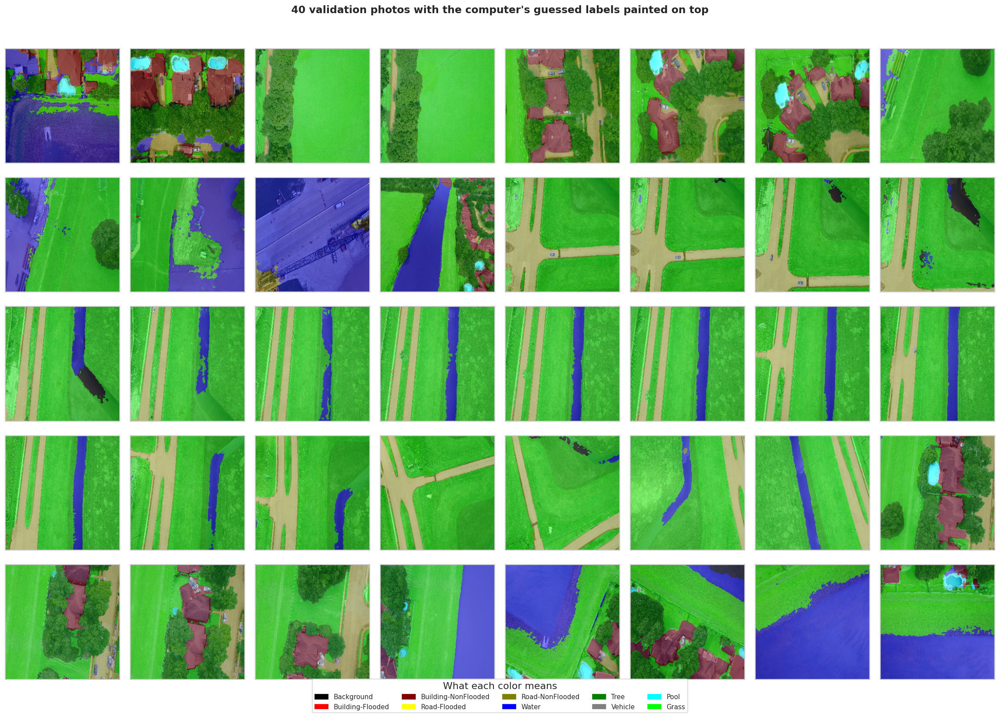

In [21]:
# ============================================================
# VISUAL 3 -- Big mosaic: 40 real photos with the computer's
# guessed labels painted on top, so you can eyeball quality
# across many images at once, not just one or two.
# ============================================================
N_MOSAIC = 40
mosaic_imgs = val_imgs[:N_MOSAIC]
n_show = len(mosaic_imgs)
n_cols = 8
n_rows = int(np.ceil(n_show / n_cols)) if n_show else 0

if n_show > 0:
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.4 * n_cols, 2.6 * n_rows))
    axes = np.array(axes).reshape(n_rows, n_cols)

    for idx, img_path in enumerate(mosaic_imgs):
        r, c = divmod(idx, n_cols)
        ax = axes[r, c]
        mask_path = os.path.join(PSEUDO_MASK_DIRS['val'], Path(img_path).stem + '_mask.png')
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_rgb = cv2.resize(img_rgb, (256, 256))
        if os.path.exists(mask_path):
            msk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            msk = cv2.resize(msk, (256, 256), interpolation=cv2.INTER_NEAREST)
            msk = np.clip(msk, 0, NUM_CLASSES - 1)
            msk_rgb = decode_mask_rgb(msk)
            overlay = cv2.addWeighted(img_rgb, 0.55, msk_rgb, 0.45, 0)
        else:
            overlay = img_rgb
        ax.imshow(overlay)
        ax.set_xticks([]); ax.set_yticks([])

    for idx in range(n_show, n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        axes[r, c].axis('off')

    patches = [mpatches.Patch(color=np.array(COLOR_MAP[i]) / 255, label=f'{CLASS_NAMES[i]}')
               for i in range(NUM_CLASSES)]
    fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=9,
               bbox_to_anchor=(0.5, -0.03), title='What each color means')
    plt.suptitle(f'{n_show} validation photos with the computer\'s guessed labels painted on top',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, '07_mosaic_40_samples.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No validation images available for the mosaic.')

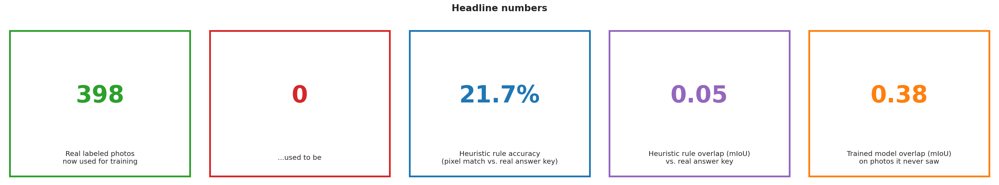

Plain-English read of the overlap score (mIoU): 1.0 = perfect match with the real
answer key, 0.0 = no overlap at all. Below ~0.35, treat guessed labels as a rough
hint only, not something to fully trust.


In [22]:
# ============================================================
# VISUAL 4 -- Scorecard: the headline numbers in giant text,
# no chart-reading skills required. Uses the accuracy numbers
# already computed in Cell 7b (pixel_accs, mean_ious) against
# the real ground-truth masks.
# ============================================================
overall_acc = float(np.mean(pixel_accs)) * 100 if pixel_accs else float('nan')
overall_miou = float(np.mean(mean_ious)) if mean_ious else float('nan')

selftrain_score_display = (f'{best_val_miou:.2f}'
                            if globals().get('best_val_miou') not in (None,) and best_val_miou >= 0
                            else 'N/A')

fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
scorecards = [
    ('Real labeled photos\nnow used for training', f'{AFTER_GT_COUNT}', '#2ca02c'),
    ('...used to be', f'{BEFORE_GT_COUNT}', '#d62728'),
    ('Heuristic rule accuracy\n(pixel match vs. real answer key)', f'{overall_acc:.1f}%', '#1f77b4'),
    ('Heuristic rule overlap (mIoU)\nvs. real answer key', f'{overall_miou:.2f}', '#9467bd'),
    ('Trained model overlap (mIoU)\non photos it never saw', selftrain_score_display, '#ff7f0e'),
]
for ax, (label, value, color) in zip(axes, scorecards):
    ax.axis('off')
    ax.text(0.5, 0.55, value, ha='center', va='center', fontsize=40, fontweight='bold', color=color)
    ax.text(0.5, 0.15, label, ha='center', va='center', fontsize=12, wrap=True)
    ax.add_patch(plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=False, edgecolor=color, linewidth=3,
                                transform=ax.transAxes))
plt.suptitle('Headline numbers', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, '08_scorecard.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Plain-English read of the overlap score (mIoU): 1.0 = perfect match with the real')
print('answer key, 0.0 = no overlap at all. Below ~0.35, treat guessed labels as a rough')
print('hint only, not something to fully trust.')

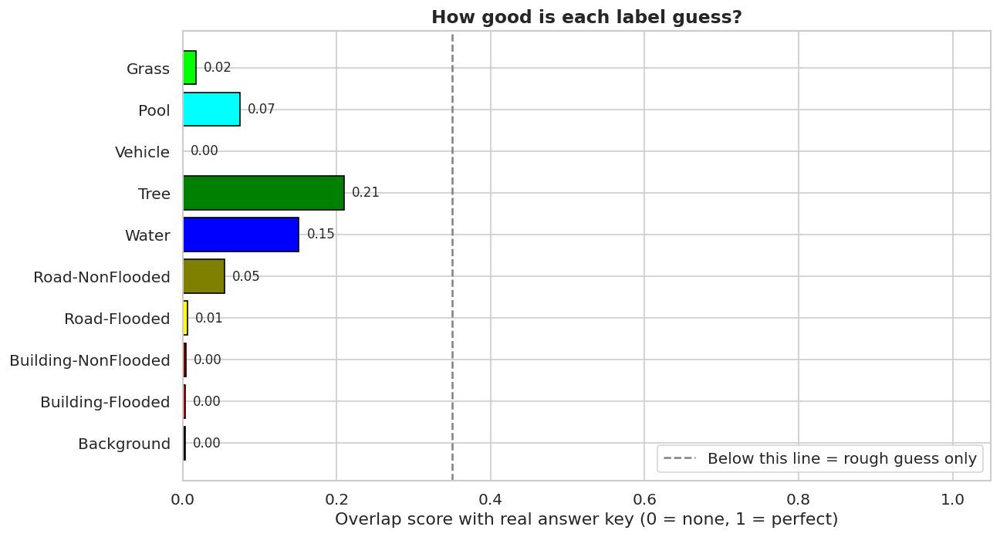

In [23]:
# ============================================================
# VISUAL 5 -- Per-class accuracy: which labels (water, road,
# building...) the computer guesses well vs. poorly, in its own
# color so it matches every other chart in this notebook.
# ============================================================
class_ids = [c for c in range(NUM_CLASSES) if c in per_class_iou_n]
class_vals = [per_class_iou_sum[c] / per_class_iou_n[c] for c in class_ids]
class_colors = [np.array(COLOR_MAP[c]) / 255 for c in class_ids]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh([CLASS_NAMES[c] for c in class_ids], class_vals, color=class_colors, edgecolor='black')
ax.axvline(0.35, color='gray', linestyle='--', linewidth=1.5, label='Below this line = rough guess only')
for bar, v in zip(bars, class_vals):
    ax.text(v + 0.01, bar.get_y() + bar.get_height()/2, f'{v:.2f}', va='center', fontsize=10)
ax.set_xlabel('Overlap score with real answer key (0 = none, 1 = perfect)')
ax.set_title('How good is each label guess?', fontsize=14, fontweight='bold')
ax.set_xlim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, '09_per_class_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()

### How to read all of this in one sentence

**Visual 1** proves the main bug is fixed (we went from throwing away every real answer key to actually using them). **Visual 2** shows the water-guessing rule now catches muddy flood water, not just clear blue water. **Visual 3** lets you eyeball 40 real examples at a glance. **Visuals 4-5** turn all of that into a few honest numbers so nobody has to just take our word for it.

All images in this section are also saved as PNG files under `plots/`, and get bundled into the ZIP file at the end of this notebook -- so they can be shared with your research partner directly.

## 📦 Cell 20 — Package Outputs

On Kaggle we SKIP zipping (it duplicates the whole working dir and caused
`OSError: [Errno 28] No space left on device` / "Your notebook tried to use more disk
space than is available" last run). All outputs are already under `/kaggle/working/`.

In [24]:
import shutil, datetime
from pathlib import Path

if IN_KAGGLE:
    # Kaggle auto-saves everything under /kaggle/working/ and lets you
    # download it from the Output tab, so zipping is unnecessary and only
    # risks running out of disk (the zip duplicates the whole working dir).
    print('='*60)
    print('KAGGLE MODE -- SKIPPING ZIP')
    print('='*60)
    print('All outputs are already saved in /kaggle/working/ :')
    for d in ['masks', 'plots', 'checkpoints', 'fed_salgate_outputs']:
        p = os.path.join(WORKING_DIR, d)
        print(f'  - {p}')
    print()
    print('Download them directly from the notebook Output / Data tab.')
else:
    timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
    zip_name = f'FedSalGate_Thesis_Outputs_{timestamp}.zip'
    zip_path = os.path.join(WORKING_DIR, zip_name)

    print('='*60)
    print('PACKAGING ALL OUTPUTS FOR DOWNLOAD')
    print('='*60)

    items = [
        ('Masks', os.path.join(WORKING_DIR, 'masks')),
        ('Plots & Figures', os.path.join(WORKING_DIR, 'plots')),
        ('Checkpoints', os.path.join(WORKING_DIR, 'checkpoints')),
        ('Excel Reports', os.path.join(WORKING_DIR, 'excel_exports')),
        ('Fed-SalGate Outputs', os.path.join(WORKING_DIR, 'fed_salgate_outputs')),
        ('Results', os.path.join(WORKING_DIR, 'results')),
    ]

    for desc, path in items:
        if os.path.exists(path):
            print(f'  [OK] {desc}')
        else:
            print(f'  [--] {desc} (empty)')

    usage = shutil.disk_usage(WORKING_DIR)
    free_gb = usage.free / 1e9
    print(f'\nFree disk in {WORKING_DIR}: {free_gb:.2f} GB')
    if free_gb < 1.0:
        print('Too little free disk space to create a zip -- skipping.')
        print('Download the files directly from /kaggle/working/ instead.')
    else:
        print(f'Creating: {zip_name}')
        shutil.make_archive(zip_path.replace('.zip', ''), 'zip', WORKING_DIR)

        size_mb = os.path.getsize(zip_path) / 1e6
        print(f'\nDone: {zip_name} ({size_mb:.1f} MB)')
        print(f'Location: {zip_path}')
        print()
        if IN_COLAB:
            from google.colab import files
            print('Downloading to your machine...')
            files.download(zip_path)
        else:
            print(f'Saved at: {zip_path}')


KAGGLE MODE -- SKIPPING ZIP
All outputs are already saved in /kaggle/working/ :
  - /kaggle/working/masks
  - /kaggle/working/plots
  - /kaggle/working/checkpoints
  - /kaggle/working/fed_salgate_outputs

Download them directly from the notebook Output / Data tab.
